# Phase 2 Step 2 — Evaluation/Split Framework + Seasonal Naive Baseline
### Walmart M5, store `CA_1`, department `FOODS_3` — aggregate daily series

This notebook implements **only** Phase 2 Step 2:
- the chronological final-holdout split
- the reusable rolling-origin (walk-forward) backtesting framework
- the Seasonal Naive baseline (the mandatory first model)
- MAE / RMSE / MAPE evaluation, zero-protected

**Not implemented here** (see the "Next steps" section at the end):
ARIMA, SARIMA, Holt-Winters, Croston, TSB, XGBoost, LSTM/GRU, Prophet.

Input: `data/processed/aggregate_ca1_foods3.parquet` — the CA_1/FOODS_3
aggregate series already built in Phase 1 (`date`, `sales`). This
notebook does not modify any Phase 1 file or Phase 1 output.

Run `python -m src.analysis.demand_classification` first if the input
file below doesn't exist yet (it is what produces the aggregate
series).

In [1]:
import sys
from pathlib import Path

def _find_project_root(start: Path) -> Path:
    """Walk up from `start` until a directory containing config.yaml is
    found. Jupyter's kernel working directory isn't consistent across
    setups (often the notebook's own folder, sometimes the launch
    directory), so this avoids assuming which one it is.
    """
    for candidate in [start, *start.parents]:
        if (candidate / "config.yaml").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find config.yaml in any parent directory of "
        f"'{start}'. Run this notebook from within the project."
    )


PROJECT_ROOT = _find_project_root(Path.cwd())
sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.data.series_validator import run_all_series_validations
from src.data.splitter import split_final_holdout
from src.evaluation.backtesting import (
    generate_rolling_origins,
    plot_fold_forecast,
    run_backtest,
    summarize_backtest,
)
from src.models.baseline import SeasonalNaive
from src.utils.config import load_config

%matplotlib inline
pd.set_option("display.max_columns", None)

config = load_config()
print("Config loaded. Backtest settings:", config["backtest"])

Config loaded. Backtest settings: {'holdout_days': 28, 'horizon': 28, 'n_folds': 5, 'season_length': 7}


## 1. Load aggregate series

In [2]:
processed_dir = PROJECT_ROOT / config["data"]["processed_dir"]
aggregate_path = processed_dir / config["output"]["aggregate_filename"]

if not aggregate_path.exists():
    raise FileNotFoundError(
        f"'{aggregate_path}' not found. Run "
        "`python -m src.analysis.demand_classification` first."
    )

df = pd.read_parquet(aggregate_path)

# Requirement 1: convert date to datetime, sort by date. Zero-sales days
# (store closures, e.g. Christmas) are legitimate observations -- never
# forward-filled or otherwise altered here.
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

print(f"Loaded {len(df)} rows: {df['date'].min().date()} to {df['date'].max().date()}")
df.head(3)

Loaded 1941 rows: 2011-01-29 to 2016-05-22


,date,sales
0,2011-01-29,2268
1,2011-01-30,2198
2,2011-01-31,1398


## 2. Validate frequency / continuity (Requirement 1)

Daily frequency, no duplicate dates, no missing dates, a continuous date range, and no negative sales. All five are treated as critical -- any failure stops the notebook here rather than modeling over a violation silently.

In [3]:
validation_results = run_all_series_validations(df, date_col="date", sales_col="sales")

for r in validation_results:
    status = "PASS" if r.passed else "FAIL"
    print(f"[{status}] {r.name}: {r.message}")

assert all(r.passed for r in validation_results), "Requirement 1 checks failed -- see above."
print("\nAll Requirement 1 checks passed. No forward-filling was performed anywhere above.")

2026-10-12 03:28:02 | INFO     | src.data.series_validator | [daily_frequency] Daily frequency confirmed (every row exactly 1 day apart).


2026-10-12 03:28:02 | INFO     | src.data.series_validator | [no_duplicate_dates] No duplicate dates.


2026-10-12 03:28:02 | INFO     | src.data.series_validator | [no_missing_dates] No missing dates in range.


2026-10-12 03:28:02 | INFO     | src.data.series_validator | [continuous_range] Continuous: 1941 rows across a 1941-day range.


2026-10-12 03:28:02 | INFO     | src.data.series_validator | [no_negative_sales] No negative sales.


[PASS] daily_frequency: Daily frequency confirmed (every row exactly 1 day apart).
[PASS] no_duplicate_dates: No duplicate dates.
[PASS] no_missing_dates: No missing dates in range.
[PASS] continuous_range: Continuous: 1941 rows across a 1941-day range.
[PASS] no_negative_sales: No negative sales.

All Requirement 1 checks passed. No forward-filling was performed anywhere above.


## 3. Final holdout (Requirement 2)

The final `holdout_days` observations are reserved as an untouched test set. **This holdout is not used anywhere else in this notebook** -- it must not influence model selection, and Phase 2 Step 2 doesn't evaluate against it.

In [4]:
holdout_days = config["backtest"]["holdout_days"]
split = split_final_holdout(df, holdout_days=holdout_days, date_col="date")

print(f"development start:  {split.dev_start.date()}")
print(f"development end:    {split.dev_end.date()}")
print(f"final test start:   {split.test_start.date()}")
print(f"final test end:     {split.test_end.date()}")
print(f"development length: {split.dev_length} days")
print(f"final test length:  {split.test_length} days")

2026-10-12 03:28:02 | INFO     | src.data.splitter | Final holdout split:
development: 2011-01-29 -> 2016-04-24 (1913 days)
final test:  2016-04-25 -> 2016-05-22 (28 days)


development start:  2011-01-29
development end:    2016-04-24
final test start:   2016-04-25
final test end:     2016-05-22
development length: 1913 days
final test length:  28 days


## 4. Rolling-origin walk-forward backtesting framework (Requirement 3)

`run_backtest()` in `src/evaluation/backtesting.py` is model-agnostic -- it takes any forecaster implementing the `BaseForecaster` fit/predict interface (`src/models/base.py`), so every later Phase 2 model (ARIMA, SARIMA, Holt-Winters, Croston, TSB, ...) will run through this exact same function. Each fold's training window is an expanding prefix of `development` only; the final holdout from step 3 never enters this loop.

In [5]:
# A date-indexed Series is what the modeling/backtesting layer operates
# on ("set date as the time index only where appropriate" -- here, for
# fitting/predicting, as opposed to the plain-column form used above for
# validation and splitting).
dev_series = split.development.set_index("date")["sales"]

horizon = config["backtest"]["horizon"]
n_folds = config["backtest"]["n_folds"]

origins = generate_rolling_origins(len(dev_series), horizon=horizon, n_folds=n_folds)
fold_layout = pd.DataFrame(
    [
        {
            "fold": o.fold,
            "train_size": o.train_end,
            "origin_date": dev_series.index[o.train_end - 1].date(),
            "forecast_start": dev_series.index[o.test_start].date(),
            "forecast_end": dev_series.index[o.test_end - 1].date(),
        }
        for o in origins
    ]
)
print(f"{len(origins)} rolling-origin folds (expanding window, horizon={horizon} days):")
fold_layout

5 rolling-origin folds (expanding window, horizon=28 days):


,fold,train_size,origin_date,forecast_start,forecast_end
0,1,1773,2015-12-06,2015-12-07,2016-01-03
1,2,1801,2016-01-03,2016-01-04,2016-01-31
2,3,1829,2016-01-31,2016-02-01,2016-02-28
3,4,1857,2016-02-28,2016-02-29,2016-03-27
4,5,1885,2016-03-27,2016-03-28,2016-04-24


## 5. Seasonal Naive baseline (Requirement 4)

`forecast(t) = actual(t - 7)`. No learned parameters: fitting just records the last 7 observed days, and every forecast tiles that one observed week forward to cover the 28-day horizon.

In [6]:
season_length = config["backtest"]["season_length"]

results = run_backtest(
    dev_series,
    lambda: SeasonalNaive(season_length=season_length),
    horizon=horizon,
    n_folds=n_folds,
)

print(f"Ran {results[0].model_name} through {len(results)} folds.")
for r in results:
    print(f"  fold {r.fold}: origin={r.origin_date.date()} "
          f"forecast={r.forecast_start.date()}..{r.forecast_end.date()}")

2026-10-12 03:28:02 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:28:02 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:28:02 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:28:02 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:28:02 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


Ran SeasonalNaive through 5 folds.
  fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03
  fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31
  fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28
  fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27
  fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


## 6. Metrics — MAE / RMSE / MAPE (Requirement 5)

RMSE and MAE are always defined and are the primary metrics. MAPE is zero-protected: any day with `actual == 0` (store-closure days such as Christmas) is excluded from that fold's MAPE average rather than producing a division-by-zero; `mape_n_excluded` reports how many such days each fold had.

In [7]:
summary_table = summarize_backtest(results)
summary_table

,model,fold,forecast_start,forecast_end,MAE,RMSE,MAPE,mape_n_excluded,n,success,error
0,SeasonalNaive,1,2015-12-07,2016-01-03,253.392857,409.046234,11.308059,1,28,True,None
1,SeasonalNaive,2,2016-01-04,2016-01-31,323.928571,390.988856,16.034750,0,28,True,None
2,SeasonalNaive,3,2016-02-01,2016-02-28,289.142857,333.591281,14.603077,0,28,True,None
3,SeasonalNaive,4,2016-02-29,2016-03-27,189.571429,241.612884,8.673877,0,28,True,None
4,SeasonalNaive,5,2016-03-28,2016-04-24,226.714286,270.010185,9.790064,0,28,True,None


In [8]:
print("Seasonal Naive -- mean across folds:")
print(f"  MAE:  {summary_table['MAE'].mean():.2f}")
print(f"  RMSE: {summary_table['RMSE'].mean():.2f}")
mape_valid = summary_table['MAPE'].dropna()
if len(mape_valid) > 0:
    print(f"  MAPE: {mape_valid.mean():.2f}% (over {len(mape_valid)}/{len(summary_table)} "
          f"folds with a valid MAPE; {int(summary_table['mape_n_excluded'].sum())} "
          f"zero-actual day(s) excluded in total across all folds)")
else:
    print("  MAPE: not computable in any fold (every fold had only zero actuals -- not expected here)")

Seasonal Naive -- mean across folds:
  MAE:  256.55
  RMSE: 329.05
  MAPE: 12.08% (over 5/5 folds with a valid MAPE; 1 zero-actual day(s) excluded in total across all folds)


## 7. Forecast-vs-actual plot (Requirement 6)

One plot for the Seasonal Naive baseline: the most recent fold (closest to the final holdout), as the most relevant single illustration of how the baseline tracks real demand.

In [9]:
reports_dir = PROJECT_ROOT / config["reports"]["phase2_dir"]
reports_dir.mkdir(parents=True, exist_ok=True)
plot_path = reports_dir / config["phase2"]["seasonal_naive_plot_filename"]

last_fold = results[-1]
ax = plot_fold_forecast(last_fold)
ax.figure.tight_layout()
ax.figure.savefig(plot_path, dpi=150)
print(f"Saved plot to {plot_path}")
plt.show()

Saved plot to /home/claude/work/intermittent-retail-demand-forecasting/reports/phase2/seasonal_naive_forecast_vs_actual.png


## 8. Save outputs (Requirement 6)

Per-fold forecasts to `artifacts/forecasts/`, the summary metrics table to `artifacts/metrics/`.

In [10]:
forecasts_dir = PROJECT_ROOT / config["phase2"]["forecasts_dir"]
metrics_dir = PROJECT_ROOT / config["phase2"]["metrics_dir"]
forecasts_dir.mkdir(parents=True, exist_ok=True)
metrics_dir.mkdir(parents=True, exist_ok=True)

# Long-format per-fold, per-day forecasts (model, fold, date, actual, predicted).
forecast_rows = []
for r in results:
    for date, actual, predicted in zip(r.dates, r.actuals, r.predictions):
        forecast_rows.append({
            "model": r.model_name,
            "fold": r.fold,
            "date": date.date(),
            "actual": actual,
            "predicted": predicted,
        })
forecasts_long = pd.DataFrame(forecast_rows)

forecasts_path = forecasts_dir / config["phase2"]["seasonal_naive_forecasts_filename"]
metrics_path = metrics_dir / config["phase2"]["seasonal_naive_metrics_filename"]

forecasts_long.to_csv(forecasts_path, index=False)
summary_table.to_csv(metrics_path, index=False)

print(f"Saved {len(forecasts_long)} forecast rows to {forecasts_path}")
print(f"Saved {len(summary_table)} fold summaries to {metrics_path}")

Saved 140 forecast rows to /home/claude/work/intermittent-retail-demand-forecasting/artifacts/forecasts/seasonal_naive_backtest_forecasts.csv
Saved 5 fold summaries to /home/claude/work/intermittent-retail-demand-forecasting/artifacts/metrics/seasonal_naive_backtest_metrics.csv


## 3. Stationarity — ADF Test (Phase 2 Step 3)

Most classical time-series models (ARIMA/SARIMA/Holt-Winters, up
next) assume the series they're fit on is **stationary** -- its mean,
variance, and autocorrelation structure don't change over time. Fitting
them on a non-stationary series as-is produces unreliable coefficients
and misleading forecasts, which is why this check comes before any of
those models are implemented.

**Augmented Dickey-Fuller (ADF) test, null hypothesis (H0):** the
series has a unit root (is non-stationary).
- p-value < 0.05 → reject H0 → evidence of stationarity
- p-value ≥ 0.05 → fail to reject H0 → insufficient evidence of stationarity

This is a statistical test, not proof either way: rejecting H0 doesn't
prove stationarity absolutely, and failing to reject it doesn't prove
non-stationarity. As in section 3 above, this uses **development data
only** (2011-01-29 to 2016-04-24) -- the final 28-day holdout is never
touched here.

In [11]:
from src.analysis.diagnostics import adf_test, first_difference, plot_stationarity_diagnostic

adf_original = adf_test(dev_series)
print(adf_original.summary("CA_1/FOODS_3 aggregate sales (development, original)"))

2026-10-12 03:28:05 | INFO     | src.analysis.diagnostics | 
ADF test on series:
  statistic: -2.3713
  p-value:   0.150006
  n_lags:    26
  n_obs:     1886
  critical values: 1%: -3.4338, 5%: -2.8631, 10%: -2.5676
  p-value >= 0.05 -> fail to reject H0 -> insufficient evidence of stationarity


ADF test on CA_1/FOODS_3 aggregate sales (development, original):
  statistic: -2.3713
  p-value:   0.150006
  n_lags:    26
  n_obs:     1886
  critical values: 1%: -3.4338, 5%: -2.8631, 10%: -2.5676
  p-value >= 0.05 -> fail to reject H0 -> insufficient evidence of stationarity


### Result: original series

See the printed statistic, p-value, lag count, observation count, and
critical values above. The conclusion follows directly from the
decision rule stated above -- whichever way it comes out, the cell
below reacts to the actual computed `adf_original.is_stationary`,
rather than assuming an outcome.

In [12]:
dev_diff = None
adf_diff = None

if not adf_original.is_stationary:
    print("Original series: insufficient evidence of stationarity -> first-differencing it.\n")
    dev_diff = first_difference(dev_series)
    adf_diff = adf_test(dev_diff)
    print(adf_diff.summary("first-differenced CA_1/FOODS_3 aggregate sales (development)"))
else:
    print("Original series: evidence of stationarity -> no differencing applied.")
    print("(Per Requirement 3, second differencing is never applied automatically regardless.)")

2026-10-12 03:28:05 | INFO     | src.analysis.diagnostics | 
ADF test on series:
  statistic: -19.1286
  p-value:   0.000000
  n_lags:    26
  n_obs:     1885
  critical values: 1%: -3.4338, 5%: -2.8631, 10%: -2.5676
  p-value < 0.05 -> reject H0 -> evidence of stationarity


Original series: insufficient evidence of stationarity -> first-differencing it.

ADF test on first-differenced CA_1/FOODS_3 aggregate sales (development):
  statistic: -19.1286
  p-value:   0.000000
  n_lags:    26
  n_obs:     1885
  critical values: 1%: -3.4338, 5%: -2.8631, 10%: -2.5676
  p-value < 0.05 -> reject H0 -> evidence of stationarity


### Conclusion

The cell below prints the real, computed verdict for the original
series and -- if differencing was required -- the differenced series.

That verdict decides whether `d=0` or `d=1` looks like the right
starting point for ARIMA/SARIMA, not the full set of orders (p, q, P,
D, Q, seasonal period), which stays a separate, later decision ("do
not tune ARIMA orders yet", per the Step 3 instructions). No
ARIMA/SARIMA/Holt-Winters model is fit anywhere in this notebook.

In [13]:
stationary_word = (
    "stationary (ADF rejects the unit-root null)"
    if adf_original.is_stationary
    else "non-stationary (ADF fails to reject the unit-root null)"
)
diff_word = (
    "not required"
    if adf_original.is_stationary
    else (
        f"first differencing applied, and the differenced series is "
        f"{'stationary' if adf_diff.is_stationary else 'still not stationary by this test'} "
        f"(p-value {adf_diff.p_value:.6g})"
    )
)
print(f"Original series is {stationary_word}.")
print(f"Differencing: {diff_word}.")
short_tag = "stationary" if adf_original.is_stationary else "non-stationary"


Original series is non-stationary (ADF fails to reject the unit-root null).
Differencing: first differencing applied, and the differenced series is stationary (p-value 0).


### Plot: original vs. first-differenced development series

Saved plot to /home/claude/work/intermittent-retail-demand-forecasting/reports/phase2/stationarity_adf_diagnostic.png


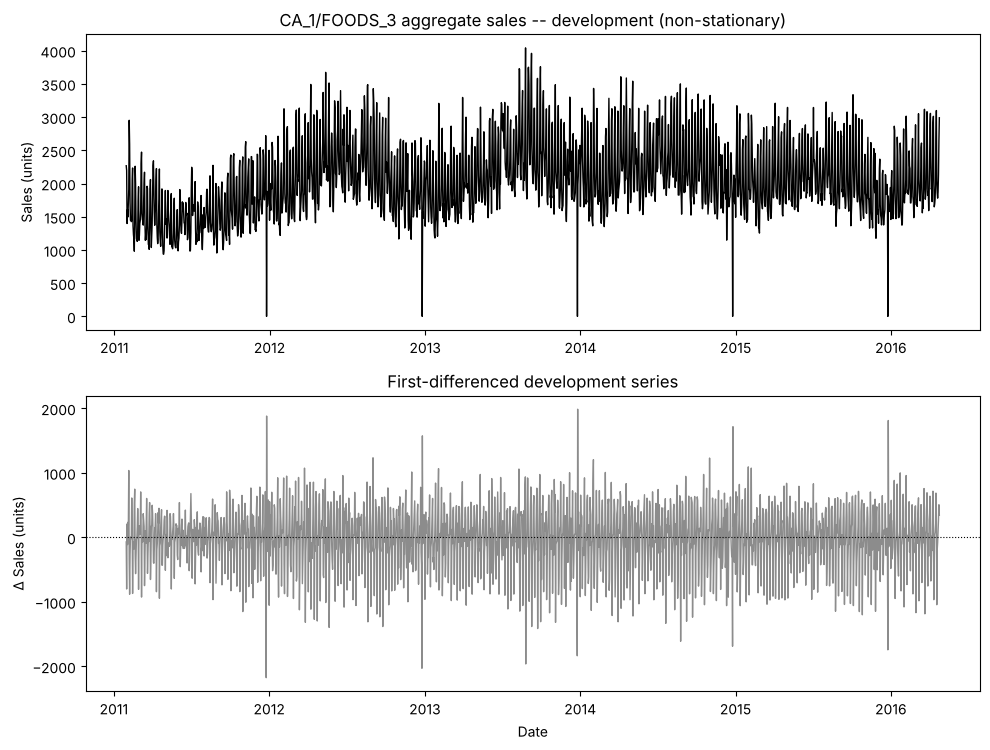

In [14]:
plot_path = reports_dir / "stationarity_adf_diagnostic.png"

fig = plot_stationarity_diagnostic(
    dev_series,
    dev_diff,
    original_label=f"CA_1/FOODS_3 aggregate sales -- development ({short_tag})",
    differenced_label="First-differenced development series" if dev_diff is not None else "",
)
fig.savefig(plot_path, dpi=150)
print(f"Saved plot to {plot_path}")
plt.show()

## 4. ACF / PACF and Candidate ARIMA Orders (Phase 2 Step 4)

This is the Box-Jenkins *order-identification* step: using the
autocorrelation function (ACF) and partial autocorrelation function
(PACF) of the differenced series to read off **candidate** ARIMA/SARIMA
orders, then cross-checking those candidates against `pmdarima`'s
automated `auto_arima` search. **No forecasting model (ARIMA, SARIMA,
Holt-Winters, Croston, TSB, XGBoost, LSTM/GRU, Prophet) is fit anywhere
in this notebook** -- that is explicitly a later step.

**Builds directly on Section 3 (ADF test) above**, which already
established, on development data only:
- original development series: ADF statistic -2.3713, p-value 0.150006 → non-stationary
- first-differenced development series: ADF statistic -19.1286, p-value ≈ 0.000000 → stationary

&rarr; **d = 1**. This section reuses the exact same `dev_diff` computed
in Section 3 (`first_difference(dev_series)`) rather than differencing
again -- per the Step 4 instructions, second differencing is never
applied.

As with every diagnostic in this notebook, everything below uses
**development data only** (2011-01-29 to 2016-04-24); the final 28-day
holdout (2016-04-25 to 2016-05-22) is never touched.

**What follows:**
1. ACF and PACF of `dev_diff`, computed out to 60 lags, with particular
   attention to lags 1, 2, ..., 7, 14, 21, 28, 35, 42, 56 (the weekly
   seasonal lag, 7, is especially important for daily retail data).
2. A written interpretation of notable spikes, weekly-seasonality
   evidence, and plausible candidate (p, q) -- read off the plots, not
   asserted in advance.
3. A `pmdarima.auto_arima` cross-check (d fixed at 1, seasonal period
   m=7), compared against the ACF/PACF reading rather than accepted on
   its own.

ACF/PACF (and auto_arima) only ever *suggest candidate orders*. Final
order selection is decided later, via model fitting, information
criteria (AIC/BIC), and backtesting -- never via the final holdout.

In [15]:
from src.analysis.diagnostics import (
    LAGS_OF_INTEREST,
    SEASONAL_PERIOD,
    compute_acf_pacf,
    plot_acf_pacf,
    plot_seasonal_lag7_diagnostic,
    run_auto_arima_cross_check,
)

assert dev_diff is not None, (
    "Section 3 (ADF test) determined the development series needs "
    "first-differencing (d=1); re-run that section above first."
)

print("d = 1 (established in Section 3 via the ADF test).")
print(
    f"Reusing dev_diff = first_difference(dev_series): {len(dev_diff)} observations, "
    f"{dev_diff.index.min().date()} to {dev_diff.index.max().date()} "
    "(development only -- never the final holdout)."
)

d = 1 (established in Section 3 via the ADF test).
Reusing dev_diff = first_difference(dev_series): 1912 observations, 2011-01-30 to 2016-04-24 (development only -- never the final holdout).


### ACF and PACF at the lags of interest

Real, computed ACF/PACF values (and whether each sits outside its own
95% significance band) at lags 1-7, then the weekly multiples through
56 -- the lags Step 4 asks us to pay particular attention to.

In [16]:
acf_pacf_result = compute_acf_pacf(dev_diff, nlags=60, alpha=0.05)
notable_table = acf_pacf_result.notable_lags_table(lags_of_interest=LAGS_OF_INTEREST)
notable_table

,lag,acf,acf_notable,pacf,pacf_notable
0,1,0.110731,True,0.110731,True
1,2,-0.254594,True,-0.270168,True
2,3,-0.345360,True,-0.305399,True
3,4,-0.326509,True,-0.398030,True
4,5,-0.231508,True,-0.557752,True
5,6,0.208211,True,-0.457537,True
6,7,0.679165,True,0.178298,True
7,14,0.679326,True,0.168205,True
8,21,0.658677,True,0.058453,True
9,28,0.642302,True,-0.013825,False


### Plots

Two figures, both saved under `reports/phase2/`:
1. **`acf_pacf_development.png`** -- combined ACF + PACF, lags of
   interest (1-7, weekly multiples to 56) highlighted in orange.
2. **`seasonal_lag7_diagnostic.png`** -- a lag-7 scatter plus the ACF
   restricted to the weekly multiples, as a focused view of the
   weekly-seasonality question.

Saved plot to /home/claude/work/intermittent-retail-demand-forecasting/reports/phase2/acf_pacf_development.png


Saved plot to /home/claude/work/intermittent-retail-demand-forecasting/reports/phase2/seasonal_lag7_diagnostic.png


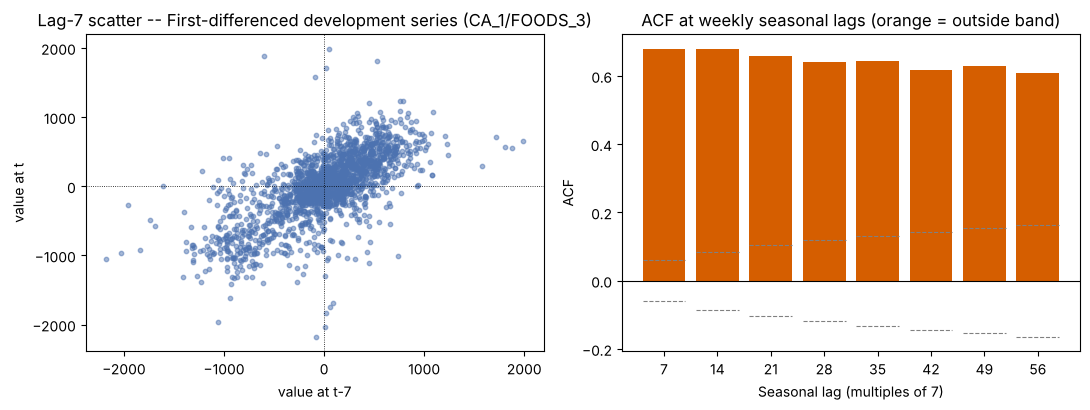

In [17]:
fig, _ = plot_acf_pacf(
    dev_diff,
    nlags=60,
    highlight_lags=LAGS_OF_INTEREST,
    series_label="First-differenced development series (CA_1/FOODS_3)",
)
acf_pacf_plot_path = reports_dir / "acf_pacf_development.png"
fig.savefig(acf_pacf_plot_path, dpi=150)
print(f"Saved plot to {acf_pacf_plot_path}")
plt.show()

seasonal_fig = plot_seasonal_lag7_diagnostic(
    dev_diff,
    nlags=60,
    seasonal_period=SEASONAL_PERIOD,
    series_label="First-differenced development series (CA_1/FOODS_3)",
)
seasonal_plot_path = reports_dir / "seasonal_lag7_diagnostic.png"
seasonal_fig.savefig(seasonal_plot_path, dpi=150)
print(f"Saved plot to {seasonal_plot_path}")
plt.show()

### Interpretation -- notable spikes, weekly seasonality, candidate orders

**Read directly off the computed numbers above (table + plots), not asserted in advance.**

**Notable ACF spikes.** Lags 1-6 are all outside the band but modest in
size (|ACF| roughly 0.11-0.35) and *alternate in sign* (+, -, -, -, -,
+) -- a short-memory, oscillating pattern consistent with leftover
day-of-week structure. Far more striking: **every one of the 60 lags
inspected has |ACF| outside the 95% band** -- the correlogram never
decays into the band anywhere in this window. In particular, ACF is
strongly positive and barely decaying at *every* weekly multiple (7,
14, 21, 28, 35, 42, 56 ≈ 0.68 → 0.61), rather than fading out after the
first one or two. A classic "cuts off after lag q" MA signature is not
present here -- the dominant feature is the slow-decaying weekly echo.

**Notable PACF spikes.** PACF is significant continuously from lag 1
through lag 8 (its largest magnitude is at lag 5, |PACF| ≈ 0.56), then
turns sparse and intermittent beyond lag 8 -- still crossing the band
occasionally near later seasonal multiples (e.g. 11-14, 19-21, 23-27)
but just as often not (9-10, 15-18, 28-31, and notably **not** at the
2-month multiples 28 and 56). That dense initial run followed by a
sparse/intermittent tail is the textbook PACF "cutoff" signature.

**Evidence for weekly seasonality.** Two independent signals agree: (1)
ACF is strongly positive (≈0.6-0.68) at literally every multiple of 7
out to 56, decaying only slowly across 8 weeks -- a single ordinary
(non-seasonal) difference has clearly *not* removed the weekly cycle;
(2) the lag-7 scatter and the seasonal-lag bar chart (plots above) show
the same pattern directly. This points toward needing seasonal AR/MA
terms and/or seasonal differencing (D) on top of d=1 -- which order
component ends up doing that work is exactly what the auto_arima
cross-check below, and later model fitting, help resolve.

**Plausible candidate p (non-seasonal AR order).** The PACF's dense
significant run (lags 1-8, peak magnitude at lag 5) suggests **p in
roughly the 5-8 range** as a starting candidate.

**Plausible candidate q (non-seasonal MA order).** ACF gives **no clean
cutoff** here -- it stays outside the band across the entire 60-lag
window because the weekly component dominates it. A clean q cannot
honestly be read off this plot; **q in a low 0-2 range** is offered only
as a conventional, low-confidence starting point, to be resolved by
fitting and AIC/BIC rather than by the correlogram.

**These are candidates only.** Final (p, d, q) and (P, D, Q, 7) are
decided later via model fitting, information criteria, and backtesting
-- never from this plot alone, and never from the final holdout.

In [18]:
# A focused look at just the weekly multiples -- the specific evidence
# the weekly-seasonality claim above is based on.
notable_table[notable_table["lag"] % SEASONAL_PERIOD == 0]

,lag,acf,acf_notable,pacf,pacf_notable
6,7,0.679165,True,0.178298,True
7,14,0.679326,True,0.168205,True
8,21,0.658677,True,0.058453,True
9,28,0.642302,True,-0.013825,False
10,35,0.642436,True,0.096465,True
11,42,0.616787,True,0.049360,True
12,56,0.607685,True,0.032530,False


### `auto_arima` cross-check

Runs `pmdarima.auto_arima` on the **raw development series** (not
`dev_diff` -- auto_arima applies its own differencing internally from
`d`, so handing it the already-differenced series would double-difference
it, which Step 4's instructions explicitly rule out).

- `d=1` fixed (Section 3's result -- not re-searched).
- Non-seasonal search range: `p` up to 7, `q` up to 7.
- Seasonal: `m=7` (weekly), `P`/`Q` up to 2, `D` left to auto_arima's own
  internal seasonal-differencing test rather than fixed.
- Development data only; the final holdout is never passed in.

In [19]:
auto_arima_result = run_auto_arima_cross_check(
    dev_series,  # raw, undifferenced -- see note above
    d=1,
    seasonal_m=SEASONAL_PERIOD,
    max_p=7,
    max_q=7,
    max_P=2,
    max_Q=2,
)
print(auto_arima_result.summary())

2026-10-12 03:30:29 | INFO     | src.analysis.diagnostics | 
auto_arima candidate (n_obs=1913):
  ARIMA(6, 1, 1)
  SARIMA(6, 1, 1)(0,0,2)[7]
  AIC: 26793.0236


auto_arima candidate (n_obs=1913):
  ARIMA(6, 1, 1)
  SARIMA(6, 1, 1)(0,0,2)[7]
  AIC: 26793.0236


### Comparing `auto_arima` against the ACF/PACF reading (viva cross-check)

**auto_arima's candidate:** ARIMA(6, 1, 1), seasonally SARIMA(6, 1,
1)(0, 0, 2)[7], AIC ≈ 26793.0, fit on exactly 1913 development
observations (confirms no holdout leakage -- 1913 is `dev_series`'s own
length, not 1913 + 28).

**Where it agrees with the plots:** p = 6 falls inside the 5-8 range
the PACF cutoff suggested; q = 1 falls inside the loose 0-2 range
offered for q. The non-seasonal order is a reasonable match.

**Where it's worth questioning, not blindly accepting:** auto_arima
chose **D = 0** (no seasonal differencing) and instead leaned on a
seasonal MA term (Q = 2) to absorb the weekly pattern. Reading the ACF
plot alone -- strong, barely-decaying spikes at *every* weekly multiple
out to 56 -- a human analyst might well have guessed a seasonal
difference (D = 1) was needed. auto_arima's internal seasonal-stationarity
test disagrees. Both are plausible; this diagnostic step alone doesn't
settle it. That disagreement is a concrete example of the stated
approach:

> *"We used ACF/PACF to understand the correlation structure and
> auto_arima as an efficient order search; the plots were used as a
> diagnostic cross-check."*

The D = 0 vs. D = 1 question (along with the exact final p and q) is
left open here, to be resolved later by actually fitting candidate
models and comparing AIC/BIC and backtest performance -- not by this
notebook, and never by the final 28-day holdout.

In [20]:
print("Section 4 summary (Phase 2 Step 4) -- diagnostics only, no model fit:\n")
print(f"  d (from Section 3 ADF test):        1")
print(f"  PACF-based candidate p:             5-8 (dense significant run, lags 1-8)")
print(f"  ACF-based candidate q:              0-2 (no clean cutoff; low-confidence default)")
print(f"  auto_arima candidate ARIMA(p,d,q):  {auto_arima_result.order}")
print(
    f"  auto_arima candidate SARIMA order:  {auto_arima_result.seasonal_order} "
    f"(period m={SEASONAL_PERIOD})"
)
print(f"  auto_arima AIC:                     {auto_arima_result.aic:.4f}")
print(
    f"  auto_arima fit on n_obs:            {auto_arima_result.n_obs} "
    f"(development only: {dev_series.index.min().date()} to {dev_series.index.max().date()})"
)
print()
print(
    "No ARIMA / SARIMA / Holt-Winters / Croston / TSB / XGBoost / LSTM-GRU / Prophet "
    "model has been fit anywhere in this notebook. Final order selection is deferred "
    "to model fitting + information criteria + backtesting -- never the final holdout."
)

Section 4 summary (Phase 2 Step 4) -- diagnostics only, no model fit:

  d (from Section 3 ADF test):        1
  PACF-based candidate p:             5-8 (dense significant run, lags 1-8)
  ACF-based candidate q:              0-2 (no clean cutoff; low-confidence default)
  auto_arima candidate ARIMA(p,d,q):  (6, 1, 1)
  auto_arima candidate SARIMA order:  (0, 0, 2, 7) (period m=7)
  auto_arima AIC:                     26793.0236
  auto_arima fit on n_obs:            1913 (development only: 2011-01-29 to 2016-04-24)

No ARIMA / SARIMA / Holt-Winters / Croston / TSB / XGBoost / LSTM-GRU / Prophet model has been fit anywhere in this notebook. Final order selection is deferred to model fitting + information criteria + backtesting -- never the final holdout.


## 5. ARIMA (Phase 2 Step 5)

Non-seasonal ARIMA(6, 1, 1) -- the Section 4 ACF/PACF + `auto_arima`
candidate order, fixed here rather than re-searched. Fit via
`statsmodels.tsa.statespace.sarimax.SARIMAX` with the seasonal
component switched off (`seasonal_order=(0, 0, 0, 0)`), through the
same `run_backtest()` used for Seasonal Naive above: one fresh
`ARIMAForecaster` is fit per development fold, trained only on that
fold's prefix, forecasting the same 28-day horizon.

SARIMA (Section 6) reuses this exact model class (`SARIMAX`) but is its
own, separate `.fit()` call on its own, separate specification --
ARIMA and SARIMA are never two readings of one combined `auto_arima`
object; Section 4's `auto_arima_result` was a diagnostic cross-check
only.

In [21]:
import numpy as np

from src.models.arima import ARIMAForecaster
from src.evaluation.comparison import (
    combine_backtest_summaries,
    plot_model_comparison,
    summarize_model_means,
)

# dev_series is already a continuous daily series -- Section 2's
# Requirement-1 checks verified that. `asfreq("D")` only attaches that
# frequency to the index explicitly; it changes no values (asserted
# below). Doing this just for the Step 5 models avoids a spurious
# statsmodels "No frequency information was provided" warning on every
# fold/model, so the warnings that actually matter (see the diagnostics
# tables below) aren't buried in noise. Seasonal Naive above is
# untouched and keeps using plain `dev_series`.
dev_series_d = dev_series.asfreq("D")
assert np.array_equal(dev_series_d.to_numpy(dtype=float), dev_series.to_numpy(dtype=float))

arima_order = tuple(config["models"]["arima_order"])
print(f"ARIMA order (p,d,q) = {arima_order}  "
      f"(matches Section 4 auto_arima candidate: {auto_arima_result.order})")

arima_results = run_backtest(
    dev_series_d,
    lambda: ARIMAForecaster(order=arima_order),
    horizon=horizon,
    n_folds=n_folds,
)
print(f"\nRan {arima_results[0].model_name} through {len(arima_results)} folds.")
for r in arima_results:
    status = "OK" if r.success else f"FAILED: {r.error}"
    print(f"  fold {r.fold}: origin={r.origin_date.date()} "
          f"forecast={r.forecast_start.date()}..{r.forecast_end.date()}  [{status}]")

ARIMA order (p,d,q) = (6, 1, 1)  (matches Section 4 auto_arima candidate: (6, 1, 1))


2026-10-12 03:30:29 | WARNING  | src.models.arima | [ARIMA(6, 1, 1)] fit on 1773 obs raised 1 warning(s): EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.


2026-10-12 03:30:29 | INFO     | src.evaluation.backtesting | [ARIMA(6, 1, 1)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:30:30 | WARNING  | src.models.arima | [ARIMA(6, 1, 1)] fit on 1801 obs raised 1 warning(s): EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.


2026-10-12 03:30:30 | INFO     | src.evaluation.backtesting | [ARIMA(6, 1, 1)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:30:31 | WARNING  | src.models.arima | [ARIMA(6, 1, 1)] fit on 1829 obs raised 1 warning(s): EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.


2026-10-12 03:30:31 | INFO     | src.evaluation.backtesting | [ARIMA(6, 1, 1)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:30:32 | WARNING  | src.models.arima | [ARIMA(6, 1, 1)] fit on 1857 obs raised 1 warning(s): EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.


2026-10-12 03:30:32 | INFO     | src.evaluation.backtesting | [ARIMA(6, 1, 1)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:30:32 | WARNING  | src.models.arima | [ARIMA(6, 1, 1)] fit on 1885 obs raised 1 warning(s): EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.


2026-10-12 03:30:32 | INFO     | src.evaluation.backtesting | [ARIMA(6, 1, 1)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24



Ran ARIMA(6, 1, 1) through 5 folds.
  fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03  [OK]
  fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31  [OK]
  fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28  [OK]
  fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27  [OK]
  fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24  [OK]


### ARIMA — fold metrics, and AIC per fold (with its training window)

AIC is recorded per fold alongside that fold's own training-window
size. AIC values from different folds are fit on different amounts of
data and are **not** directly comparable to each other as if competing
for the same prize -- a lower AIC on a larger-window fold does not mean
"a better model" than a higher AIC on a smaller-window fold, and in
neither case does a lower AIC by itself imply better out-of-sample
forecast accuracy. That question is answered by the backtest MAE/RMSE
below, not by AIC.

In [22]:
arima_summary = summarize_backtest(arima_results)
arima_summary

,model,fold,forecast_start,forecast_end,MAE,RMSE,MAPE,mape_n_excluded,n,success,error
0,"ARIMA(6, 1, 1)",1,2015-12-07,2016-01-03,217.252853,388.061272,9.552880,1,28,True,None
1,"ARIMA(6, 1, 1)",2,2016-01-04,2016-01-31,323.119071,414.812077,15.508555,0,28,True,None
2,"ARIMA(6, 1, 1)",3,2016-02-01,2016-02-28,244.841410,292.927630,11.693578,0,28,True,None
3,"ARIMA(6, 1, 1)",4,2016-02-29,2016-03-27,219.786020,300.952378,9.831356,0,28,True,None
4,"ARIMA(6, 1, 1)",5,2016-03-28,2016-04-24,223.054220,270.092101,9.992711,0,28,True,None


In [23]:
arima_diagnostics = pd.DataFrame([
    {
        "fold": r.fold,
        "train_end": r.origin_date.date(),
        "n_obs_fit": r.diagnostics.get("n_obs_fit"),
        "AIC": r.diagnostics.get("aic"),
        "converged": r.diagnostics.get("converged"),
        "n_warnings": len(r.diagnostics.get("convergence_warnings", [])),
        "warnings": "; ".join(r.diagnostics.get("convergence_warnings", [])) or None,
    }
    for r in arima_results
])
arima_diagnostics

,fold,train_end,n_obs_fit,AIC,converged,n_warnings,warnings
0,1,2015-12-06,1773,25177.307259,True,1,EstimationWarning: Non-stationary starting aut...
1,2,2016-01-03,1801,25605.220991,True,1,EstimationWarning: Non-stationary starting aut...
2,3,2016-01-31,1829,25994.829932,True,1,EstimationWarning: Non-stationary starting aut...
3,4,2016-02-28,1857,26383.740264,True,1,EstimationWarning: Non-stationary starting aut...
4,5,2016-03-27,1885,26771.714136,True,1,EstimationWarning: Non-stationary starting aut...


### ARIMA — mean across folds, vs. Seasonal Naive

In [24]:
arima_mae_mean = arima_summary["MAE"].mean()
arima_rmse_mean = arima_summary["RMSE"].mean()
arima_mape_valid = arima_summary["MAPE"].dropna()
arima_mape_mean = arima_mape_valid.mean() if len(arima_mape_valid) else None

print("ARIMA -- mean across folds:")
print(f"  MAE:  {arima_mae_mean:.2f}")
print(f"  RMSE: {arima_rmse_mean:.2f}")
if arima_mape_mean is not None:
    print(f"  MAPE: {arima_mape_mean:.2f}% (over {len(arima_mape_valid)}/{len(arima_summary)} folds with a valid MAPE)")
else:
    print("  MAPE: not computable in any fold")

sn_mae_mean = summary_table["MAE"].mean()
sn_rmse_mean = summary_table["RMSE"].mean()
print(f"\nSeasonal Naive mean MAE/RMSE (Section 6, unchanged): {sn_mae_mean:.2f} / {sn_rmse_mean:.2f}")
print(f"ARIMA beats Seasonal Naive on MAE:  {arima_mae_mean < sn_mae_mean}")
print(f"ARIMA beats Seasonal Naive on RMSE: {arima_rmse_mean < sn_rmse_mean}")

ARIMA -- mean across folds:
  MAE:  245.61
  RMSE: 333.37
  MAPE: 11.32% (over 5/5 folds with a valid MAPE)

Seasonal Naive mean MAE/RMSE (Section 6, unchanged): 256.55 / 329.05
ARIMA beats Seasonal Naive on MAE:  True
ARIMA beats Seasonal Naive on RMSE: False


## 6. SARIMA (Phase 2 Step 5)

Seasonal ARIMA(6, 1, 1)(0, 0, 2, 7) -- the Section 4 `auto_arima`
seasonal candidate (m=7, weekly), fixed here rather than re-searched.
Fit via the same `SARIMAX` class as ARIMA above, but as its own
independent `.fit()` call on its own specification: `ARIMAForecaster`
and `SARIMAForecaster` are two separate classes, each producing its own
fitted result object. Neither reuses Section 4's `auto_arima_result`.

In [25]:
from src.models.sarima import SARIMAForecaster

sarima_order = tuple(config["models"]["sarima_order"])
sarima_seasonal_order = tuple(config["models"]["sarima_seasonal_order"])
print(f"SARIMA order (p,d,q) = {sarima_order}, seasonal_order (P,D,Q,m) = {sarima_seasonal_order}  "
      f"(matches Section 4 auto_arima candidate: {auto_arima_result.order}, {auto_arima_result.seasonal_order})")

sarima_results = run_backtest(
    dev_series_d,
    lambda: SARIMAForecaster(order=sarima_order, seasonal_order=sarima_seasonal_order),
    horizon=horizon,
    n_folds=n_folds,
)
print(f"\nRan {sarima_results[0].model_name} through {len(sarima_results)} folds.")
for r in sarima_results:
    status = "OK" if r.success else f"FAILED: {r.error}"
    print(f"  fold {r.fold}: origin={r.origin_date.date()} "
          f"forecast={r.forecast_start.date()}..{r.forecast_end.date()}  [{status}]")

SARIMA order (p,d,q) = (6, 1, 1), seasonal_order (P,D,Q,m) = (0, 0, 2, 7)  (matches Section 4 auto_arima candidate: (6, 1, 1), (0, 0, 2, 7))


2026-10-12 03:30:54 | WARNING  | src.models.sarima | [SARIMA(6, 1, 1)x(0, 0, 2, 7)] fit on 1773 obs raised 1 warning(s): EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.


2026-10-12 03:30:54 | INFO     | src.evaluation.backtesting | [SARIMA(6, 1, 1)x(0, 0, 2, 7)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:30:58 | WARNING  | src.models.sarima | [SARIMA(6, 1, 1)x(0, 0, 2, 7)] fit on 1801 obs raised 1 warning(s): EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.


2026-10-12 03:30:58 | INFO     | src.evaluation.backtesting | [SARIMA(6, 1, 1)x(0, 0, 2, 7)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:31:27 | WARNING  | src.models.sarima | [SARIMA(6, 1, 1)x(0, 0, 2, 7)] fit on 1829 obs raised 2 warning(s): EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.; ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals


2026-10-12 03:31:27 | INFO     | src.evaluation.backtesting | [SARIMA(6, 1, 1)x(0, 0, 2, 7)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:31:51 | WARNING  | src.models.sarima | [SARIMA(6, 1, 1)x(0, 0, 2, 7)] fit on 1857 obs raised 1 warning(s): EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.


2026-10-12 03:31:51 | INFO     | src.evaluation.backtesting | [SARIMA(6, 1, 1)x(0, 0, 2, 7)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:32:12 | WARNING  | src.models.sarima | [SARIMA(6, 1, 1)x(0, 0, 2, 7)] fit on 1885 obs raised 1 warning(s): EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.


2026-10-12 03:32:12 | INFO     | src.evaluation.backtesting | [SARIMA(6, 1, 1)x(0, 0, 2, 7)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24



Ran SARIMA(6, 1, 1)x(0, 0, 2, 7) through 5 folds.
  fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03  [OK]
  fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31  [OK]
  fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28  [OK]
  fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27  [OK]
  fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24  [OK]


### SARIMA — fold metrics, and AIC per fold (with its training window)

Same caveat as ARIMA: AIC values across folds are fit on different
training-window sizes and are not directly comparable to each other,
and a lower AIC does not by itself imply better out-of-sample accuracy.

In [26]:
sarima_summary = summarize_backtest(sarima_results)
sarima_summary

,model,fold,forecast_start,forecast_end,MAE,RMSE,MAPE,mape_n_excluded,n,success,error
0,"SARIMA(6, 1, 1)x(0, 0, 2, 7)",1,2015-12-07,2016-01-03,269.758141,411.253427,12.704939,1,28,True,None
1,"SARIMA(6, 1, 1)x(0, 0, 2, 7)",2,2016-01-04,2016-01-31,314.902290,389.475705,15.147892,0,28,True,None
2,"SARIMA(6, 1, 1)x(0, 0, 2, 7)",3,2016-02-01,2016-02-28,237.119800,273.043569,11.579170,0,28,True,None
3,"SARIMA(6, 1, 1)x(0, 0, 2, 7)",4,2016-02-29,2016-03-27,164.732529,239.878678,7.224187,0,28,True,None
4,"SARIMA(6, 1, 1)x(0, 0, 2, 7)",5,2016-03-28,2016-04-24,153.311871,197.465104,6.540912,0,28,True,None


In [27]:
sarima_diagnostics = pd.DataFrame([
    {
        "fold": r.fold,
        "train_end": r.origin_date.date(),
        "n_obs_fit": r.diagnostics.get("n_obs_fit"),
        "AIC": r.diagnostics.get("aic"),
        "converged": r.diagnostics.get("converged"),
        "n_warnings": len(r.diagnostics.get("convergence_warnings", [])),
        "warnings": "; ".join(r.diagnostics.get("convergence_warnings", [])) or None,
    }
    for r in sarima_results
])
sarima_diagnostics

,fold,train_end,n_obs_fit,AIC,converged,n_warnings,warnings
0,1,2015-12-06,1773,24783.785235,True,1,EstimationWarning: Non-stationary starting aut...
1,2,2016-01-03,1801,25261.013115,True,1,EstimationWarning: Non-stationary starting aut...
2,3,2016-01-31,1829,25604.394289,False,2,EstimationWarning: Non-stationary starting aut...
3,4,2016-02-28,1857,25994.644692,True,1,EstimationWarning: Non-stationary starting aut...
4,5,2016-03-27,1885,26365.090850,True,1,EstimationWarning: Non-stationary starting aut...


### SARIMA — mean across folds, vs. Seasonal Naive and ARIMA

In [28]:
sarima_mae_mean = sarima_summary["MAE"].mean()
sarima_rmse_mean = sarima_summary["RMSE"].mean()
sarima_mape_valid = sarima_summary["MAPE"].dropna()
sarima_mape_mean = sarima_mape_valid.mean() if len(sarima_mape_valid) else None

print("SARIMA -- mean across folds:")
print(f"  MAE:  {sarima_mae_mean:.2f}")
print(f"  RMSE: {sarima_rmse_mean:.2f}")
if sarima_mape_mean is not None:
    print(f"  MAPE: {sarima_mape_mean:.2f}% (over {len(sarima_mape_valid)}/{len(sarima_summary)} folds with a valid MAPE)")
else:
    print("  MAPE: not computable in any fold")

print(f"\nSARIMA beats Seasonal Naive on MAE:  {sarima_mae_mean < sn_mae_mean}")
print(f"SARIMA beats Seasonal Naive on RMSE: {sarima_rmse_mean < sn_rmse_mean}")
print(f"SARIMA beats ARIMA on MAE:  {sarima_mae_mean < arima_mae_mean}")
print(f"SARIMA beats ARIMA on RMSE: {sarima_rmse_mean < arima_rmse_mean}")

SARIMA -- mean across folds:
  MAE:  227.96
  RMSE: 302.22
  MAPE: 10.64% (over 5/5 folds with a valid MAPE)

SARIMA beats Seasonal Naive on MAE:  True
SARIMA beats Seasonal Naive on RMSE: True
SARIMA beats ARIMA on MAE:  True
SARIMA beats ARIMA on RMSE: True


## 7. Holt-Winters (Phase 2 Step 5)

Additive-seasonal Holt-Winters exponential smoothing
(`statsmodels.tsa.holtwinters.ExponentialSmoothing`), weekly seasonality
(`seasonal_periods=7`). Additive components only -- never multiplicative
-- because the CA_1/FOODS_3 series has exact zero-sales days (Christmas
closures), and a multiplicative seasonal or trend component cannot fit
through a true zero.

Whether to include a trend term is treated as a model-development
choice: `trend="add"` and `trend=None` are both fit and backtested
across the same 5 development folds below (never the final holdout),
and the better of the two by mean development-fold MAE -- this
project's primary error metric -- is carried forward as "the"
Holt-Winters model for the rest of this notebook.

In [29]:
from src.models.holt_winters import DEFAULT_TREND, HoltWintersForecaster

hw_add_results = run_backtest(dev_series_d, lambda: HoltWintersForecaster(trend="add"), horizon=horizon, n_folds=n_folds)
hw_none_results = run_backtest(dev_series_d, lambda: HoltWintersForecaster(trend=None), horizon=horizon, n_folds=n_folds)

hw_add_summary = summarize_backtest(hw_add_results)
hw_none_summary = summarize_backtest(hw_none_results)

hw_trend_comparison = pd.DataFrame([
    {
        "trend": "add",
        "MAE_mean": hw_add_summary["MAE"].mean(),
        "RMSE_mean": hw_add_summary["RMSE"].mean(),
        "n_failed": int((~hw_add_summary["success"]).sum()),
    },
    {
        "trend": "none",
        "MAE_mean": hw_none_summary["MAE"].mean(),
        "RMSE_mean": hw_none_summary["RMSE"].mean(),
        "n_failed": int((~hw_none_summary["success"]).sum()),
    },
])
hw_trend_comparison_path = metrics_dir / config["phase2"]["holt_winters_trend_comparison_filename"]
hw_trend_comparison.to_csv(hw_trend_comparison_path, index=False)

# Tie-break by mean MAE -- this project's metrics module documents
# MAE/RMSE as the primary pair, and MAE (unlike RMSE) weights an
# occasional large miss no more than its actual size, consistent with
# this project's locked validation rules for intermittent, zero-
# inflated demand.
winner = hw_trend_comparison.sort_values("MAE_mean").iloc[0]["trend"]
winner_trend = "add" if winner == "add" else None
match_word = "matches" if DEFAULT_TREND == winner_trend else "DOES NOT MATCH -- update the module default"
print("Holt-Winters trend=add vs trend=None, mean across the 5 development folds:")
print(hw_trend_comparison.to_string(index=False))
print(f"\nWinner by mean MAE: trend={winner!r}")
print(f"src.models.holt_winters.DEFAULT_TREND is currently {DEFAULT_TREND!r} ({match_word} this result).")

holt_winters_results = hw_add_results if winner_trend == "add" else hw_none_results
print(f"\nUsing trend={winner_trend!r} as \"the\" Holt-Winters model for the rest of this notebook.")

2026-10-12 03:32:12 | INFO     | src.evaluation.backtesting | [HoltWinters(trend=add)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:32:13 | INFO     | src.evaluation.backtesting | [HoltWinters(trend=add)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:32:13 | INFO     | src.evaluation.backtesting | [HoltWinters(trend=add)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:32:13 | INFO     | src.evaluation.backtesting | [HoltWinters(trend=add)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:32:14 | INFO     | src.evaluation.backtesting | [HoltWinters(trend=add)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:32:14 | INFO     | src.evaluation.backtesting | [HoltWinters(trend=none)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:32:14 | INFO     | src.evaluation.backtesting | [HoltWinters(trend=none)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:32:14 | INFO     | src.evaluation.backtesting | [HoltWinters(trend=none)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:32:14 | INFO     | src.evaluation.backtesting | [HoltWinters(trend=none)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:32:14 | INFO     | src.evaluation.backtesting | [HoltWinters(trend=none)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


Holt-Winters trend=add vs trend=None, mean across the 5 development folds:
trend   MAE_mean  RMSE_mean  n_failed
  add 193.349123 266.437882         0
 none 194.185162 265.786000         0

Winner by mean MAE: trend='add'
src.models.holt_winters.DEFAULT_TREND is currently 'add' (matches this result).

Using trend='add' as "the" Holt-Winters model for the rest of this notebook.


### Holt-Winters — fold metrics, and AIC per fold (for the chosen trend setting)

In [30]:
holt_winters_summary = summarize_backtest(holt_winters_results)
holt_winters_summary

,model,fold,forecast_start,forecast_end,MAE,RMSE,MAPE,mape_n_excluded,n,success,error
0,HoltWinters(trend=add),1,2015-12-07,2016-01-03,270.142772,426.717162,12.280271,1,28,True,None
1,HoltWinters(trend=add),2,2016-01-04,2016-01-31,249.620316,328.554662,11.689373,0,28,True,None
2,HoltWinters(trend=add),3,2016-02-01,2016-02-28,167.289138,207.382266,8.027012,0,28,True,None
3,HoltWinters(trend=add),4,2016-02-29,2016-03-27,143.487300,207.792623,6.381283,0,28,True,None
4,HoltWinters(trend=add),5,2016-03-28,2016-04-24,136.206089,161.742695,6.643845,0,28,True,None


In [31]:
holt_winters_diagnostics = pd.DataFrame([
    {
        "fold": r.fold,
        "train_end": r.origin_date.date(),
        "n_obs_fit": r.diagnostics.get("n_obs_fit"),
        "trend": r.diagnostics.get("trend"),
        "AIC": r.diagnostics.get("aic"),
        "n_warnings": len(r.diagnostics.get("convergence_warnings", [])),
    }
    for r in holt_winters_results
])
holt_winters_diagnostics

,fold,train_end,n_obs_fit,trend,AIC,n_warnings
0,1,2015-12-06,1773,add,19784.140160,0
1,2,2016-01-03,1801,add,20147.999576,0
2,3,2016-01-31,1829,add,20455.092694,0
3,4,2016-02-28,1857,add,20755.569226,0
4,5,2016-03-27,1885,add,21055.759694,0


### Holt-Winters — mean across folds, vs. the other models

In [32]:
hw_mae_mean = holt_winters_summary["MAE"].mean()
hw_rmse_mean = holt_winters_summary["RMSE"].mean()
hw_mape_valid = holt_winters_summary["MAPE"].dropna()
hw_mape_mean = hw_mape_valid.mean() if len(hw_mape_valid) else None

print(f"Holt-Winters (trend={winner_trend!r}) -- mean across folds:")
print(f"  MAE:  {hw_mae_mean:.2f}")
print(f"  RMSE: {hw_rmse_mean:.2f}")
if hw_mape_mean is not None:
    print(f"  MAPE: {hw_mape_mean:.2f}% (over {len(hw_mape_valid)}/{len(holt_winters_summary)} folds with a valid MAPE)")
else:
    print("  MAPE: not computable in any fold")

print(f"\nHolt-Winters beats Seasonal Naive on MAE:  {hw_mae_mean < sn_mae_mean}")
print(f"Holt-Winters beats Seasonal Naive on RMSE: {hw_rmse_mean < sn_rmse_mean}")
print(f"Holt-Winters beats ARIMA on MAE:  {hw_mae_mean < arima_mae_mean}")
print(f"Holt-Winters beats SARIMA on MAE: {hw_mae_mean < sarima_mae_mean}")

Holt-Winters (trend='add') -- mean across folds:
  MAE:  193.35
  RMSE: 266.44
  MAPE: 9.00% (over 5/5 folds with a valid MAPE)

Holt-Winters beats Seasonal Naive on MAE:  True
Holt-Winters beats Seasonal Naive on RMSE: True
Holt-Winters beats ARIMA on MAE:  True
Holt-Winters beats SARIMA on MAE: True


## 8. Save Step 5 outputs

In [33]:
def save_fold_forecasts(results, filename):
    """Long-format per-fold, per-day forecasts -- same shape as Section 8's Seasonal Naive save.

    Failed folds contribute no rows here (there is no prediction to
    save), but remain fully visible in that model's *_metrics CSV via
    the success/error columns.
    """
    rows = []
    for r in results:
        if not r.success:
            continue
        for date, actual, predicted in zip(r.dates, r.actuals, r.predictions):
            rows.append({
                "model": r.model_name,
                "fold": r.fold,
                "date": date.date(),
                "actual": actual,
                "predicted": predicted,
            })
    path = forecasts_dir / filename
    pd.DataFrame(rows).to_csv(path, index=False)
    return path


arima_forecasts_path = save_fold_forecasts(arima_results, config["phase2"]["arima_forecasts_filename"])
arima_summary.to_csv(metrics_dir / config["phase2"]["arima_metrics_filename"], index=False)

sarima_forecasts_path = save_fold_forecasts(sarima_results, config["phase2"]["sarima_forecasts_filename"])
sarima_summary.to_csv(metrics_dir / config["phase2"]["sarima_metrics_filename"], index=False)

holt_winters_forecasts_path = save_fold_forecasts(holt_winters_results, config["phase2"]["holt_winters_forecasts_filename"])
holt_winters_summary.to_csv(metrics_dir / config["phase2"]["holt_winters_metrics_filename"], index=False)

print("Saved ARIMA forecasts/metrics to      ", arima_forecasts_path)
print("Saved SARIMA forecasts/metrics to     ", sarima_forecasts_path)
print("Saved Holt-Winters forecasts/metrics to", holt_winters_forecasts_path)

Saved ARIMA forecasts/metrics to       /home/claude/work/intermittent-retail-demand-forecasting/artifacts/forecasts/arima_backtest_forecasts.csv
Saved SARIMA forecasts/metrics to      /home/claude/work/intermittent-retail-demand-forecasting/artifacts/forecasts/sarima_backtest_forecasts.csv
Saved Holt-Winters forecasts/metrics to /home/claude/work/intermittent-retail-demand-forecasting/artifacts/forecasts/holt_winters_backtest_forecasts.csv


## 9. Combined comparison — all models

Seasonal Naive, ARIMA, SARIMA, and Holt-Winters, side by side: mean
fold-level MAE/RMSE/MAPE (successful folds only), with a bar-chart
comparison of mean MAE/RMSE across models (±1 std across folds).

In [34]:
combined_summary = combine_backtest_summaries([summary_table, arima_summary, sarima_summary, holt_winters_summary])
model_means = summarize_model_means(combined_summary)
model_means

,model,n_folds,n_success,n_failed,MAE_mean,MAE_std,RMSE_mean,RMSE_std,MAPE_mean,MAPE_n_folds_valid
0,SeasonalNaive,5,5,0,256.550000,52.412863,329.049888,73.122144,12.081966,5
1,"ARIMA(6, 1, 1)",5,5,0,245.610714,44.687850,333.369092,63.864167,11.315816,5
2,"SARIMA(6, 1, 1)x(0, 0, 2, 7)",5,5,0,227.964926,68.847666,302.223297,93.825822,10.639420,5
3,HoltWinters(trend=add),5,5,0,193.349123,62.238176,266.437882,108.898871,9.004357,5


In [35]:
comparison_metrics_path = metrics_dir / config["phase2"]["model_comparison_metrics_filename"]
model_means.to_csv(comparison_metrics_path, index=False)

comparison_plot_path = reports_dir / config["phase2"]["model_comparison_plot_filename"]
ax = plot_model_comparison(model_means)
ax.figure.savefig(comparison_plot_path, dpi=150)
print(f"Saved comparison table to {comparison_metrics_path}")
print(f"Saved comparison plot to {comparison_plot_path}")
plt.show()

Saved comparison table to /home/claude/work/intermittent-retail-demand-forecasting/artifacts/metrics/model_comparison_backtest_metrics.csv
Saved comparison plot to /home/claude/work/intermittent-retail-demand-forecasting/reports/phase2/model_comparison_mae_rmse.png


### Does each model beat Seasonal Naive on development backtesting?

In [36]:
sn_row = model_means[model_means["model"] == "SeasonalNaive"].iloc[0]
sn_mae, sn_rmse = sn_row["MAE_mean"], sn_row["RMSE_mean"]
print(f"Seasonal Naive (baseline): MAE={sn_mae:.2f}  RMSE={sn_rmse:.2f}\n")
for _, row in model_means[model_means["model"] != "SeasonalNaive"].iterrows():
    model_label = row["model"]
    row_mae, row_rmse = row["MAE_mean"], row["RMSE_mean"]
    mae_beats = row_mae < sn_mae
    rmse_beats = row_rmse < sn_rmse
    mae_word = "beats" if mae_beats else "does NOT beat"
    rmse_word = "beats" if rmse_beats else "does NOT beat"
    print(f"{model_label:30s} MAE={row_mae:8.2f} ({mae_word} Seasonal Naive), "
          f"RMSE={row_rmse:8.2f} ({rmse_word} Seasonal Naive)")

Seasonal Naive (baseline): MAE=256.55  RMSE=329.05

ARIMA(6, 1, 1)                 MAE=  245.61 (beats Seasonal Naive), RMSE=  333.37 (does NOT beat Seasonal Naive)
SARIMA(6, 1, 1)x(0, 0, 2, 7)   MAE=  227.96 (beats Seasonal Naive), RMSE=  302.22 (beats Seasonal Naive)
HoltWinters(trend=add)         MAE=  193.35 (beats Seasonal Naive), RMSE=  266.44 (beats Seasonal Naive)


## 10. Phase 2 Step 5 summary

In [37]:
print("Phase 2 Step 5 summary -- ARIMA, SARIMA, Holt-Winters fit and backtested:\n")

print("Fold / date ranges (same 5 development folds as every model in this project):")
print(fold_layout.to_string(index=False))

print("\nMean MAE / RMSE / MAPE across folds (successful folds only):")
for name, summ in [("SeasonalNaive", summary_table), ("ARIMA", arima_summary),
                    ("SARIMA", sarima_summary), ("HoltWinters", holt_winters_summary)]:
    mae_m = summ["MAE"].mean()
    rmse_m = summ["RMSE"].mean()
    mape_v = summ["MAPE"].dropna()
    mape_str = f"{mape_v.mean():.2f}% (n={len(mape_v)}/{len(summ)})" if len(mape_v) else "not computable"
    print(f"  {name:15s} MAE={mae_m:8.2f}  RMSE={rmse_m:8.2f}  MAPE={mape_str}")

print("\nARIMA AIC per fold (NOT comparable across folds -- different training-window sizes):")
print(arima_diagnostics[["fold", "n_obs_fit", "AIC", "converged", "n_warnings"]].to_string(index=False))

print("\nSARIMA AIC per fold (NOT comparable across folds -- different training-window sizes):")
print(sarima_diagnostics[["fold", "n_obs_fit", "AIC", "converged", "n_warnings"]].to_string(index=False))

all_new_results = arima_results + sarima_results + holt_winters_results
n_failed_total = sum(not r.success for r in all_new_results)
print(f"\nFailed folds across ARIMA + SARIMA + Holt-Winters: {n_failed_total} / {len(all_new_results)}")
for label, res_list in [("ARIMA", arima_results), ("SARIMA", sarima_results), ("HoltWinters", holt_winters_results)]:
    for r in res_list:
        if not r.success:
            print(f"  {label} fold {r.fold} FAILED: {r.error}")

print("\nHolt-Winters trend comparison (development folds only, never the holdout):")
print(hw_trend_comparison.to_string(index=False))
print(f"Winner / model default: trend={winner_trend!r}")

print(f"\nFinal 28-day holdout ({split.test_start.date()} to {split.test_end.date()}) was "
      "NOT used anywhere in this notebook for fitting, order selection, or the Holt-Winters "
      "trend comparison above -- every model above was trained and evaluated only on "
      "`split.development`.")

Phase 2 Step 5 summary -- ARIMA, SARIMA, Holt-Winters fit and backtested:

Fold / date ranges (same 5 development folds as every model in this project):
 fold  train_size origin_date forecast_start forecast_end
    1        1773  2015-12-06     2015-12-07   2016-01-03
    2        1801  2016-01-03     2016-01-04   2016-01-31
    3        1829  2016-01-31     2016-02-01   2016-02-28
    4        1857  2016-02-28     2016-02-29   2016-03-27
    5        1885  2016-03-27     2016-03-28   2016-04-24

Mean MAE / RMSE / MAPE across folds (successful folds only):
  SeasonalNaive   MAE=  256.55  RMSE=  329.05  MAPE=12.08% (n=5/5)
  ARIMA           MAE=  245.61  RMSE=  333.37  MAPE=11.32% (n=5/5)
  SARIMA          MAE=  227.96  RMSE=  302.22  MAPE=10.64% (n=5/5)
  HoltWinters     MAE=  193.35  RMSE=  266.44  MAPE=9.00% (n=5/5)

ARIMA AIC per fold (NOT comparable across folds -- different training-window sizes):
 fold  n_obs_fit          AIC  converged  n_warnings
    1       1773 25177.307259  

## 11. Residual Diagnostics and Model Adequacy (Phase 2 Step 6)

*(Numbering note: Section 10 above is Phase 2 Step 5's own summary
section and is left untouched per this project's rule against modifying
already-approved deliverables without a demonstrated bug. The Step 6
brief's own suggested heading was "10. Residual Diagnostics...";
this notebook instead continues the numbering as Section 11, so nothing
already delivered is renumbered or overwritten.)*

This section validates the ARIMA, SARIMA, and Holt-Winters results from
Section 5-10 (Phase 2 Step 5) **before** any further forecasting method
is implemented, per the Step 6 brief. Nothing above is refit here:
every diagnostic below reads `arima_results` / `sarima_results` /
`hw_add_results` / `hw_none_results` exactly as Section 5-7 already
computed and left in this kernel.

**Training residuals vs. forecast error -- not the same thing.** Every
number in this section is an **in-sample training residual**: a fitted
model's one-step-ahead prediction error on the *same* data it was fit
on (one backtest fold's training window). This is categorically
different from the **out-of-sample forecast error** (actual − predicted
on a fold's 28-day held-out test window) that Sections 6, 7, and 9
already reported as MAE/RMSE. `src.evaluation.residuals` reads training
residuals exclusively from each forecaster's own
`fit_diagnostics()["resid"]`/`["resid_diagnostic"]` -- computed once,
inside `fit()`, directly from the fitted statsmodels result object's own
`.resid` attribute -- and never recomputes anything from a fold's
`actuals`/`predictions`. `tests/evaluation/test_residuals.py` encodes
this as an explicit regression test
(`test_training_residuals_are_not_the_oos_forecast_error`).

**Final holdout.** Nothing below reads `split.test` /
`split.test_start` / `split.test_end` for anything other than printing
a confirmation at the end of this section. Every fold diagnosed here
comes from a development-fold backtest result that was itself never fit
on, or evaluated against, the holdout.

**On "proving" a model is adequate.** No single diagnostic below --
not a residual plot, not an ACF, not a histogram, not one Ljung-Box
lag -- proves a model is adequate by itself. This caveat is restated
at the point each diagnostic is used, not just here.

In [38]:
from src.evaluation.residuals import (
    MODEL_ADEQUACY_CAVEAT,
    SUPPLEMENTARY_LJUNG_BOX_LAGS,
    build_fold_diagnostics,
    fold_summary_table,
    plot_residual_diagnostics,
    plot_residual_diagnostics_grid,
    residual_diagnostics_table,
    select_ljung_box_lag,
)

print(MODEL_ADEQUACY_CAVEAT)
print(f"\nSupplementary (weekly-multiple) Ljung-Box lags always reported: {SUPPLEMENTARY_LJUNG_BOX_LAGS}")
print("Primary lag by fold (Hyndman & Athanasopoulos' rule for seasonal data, "
      "min(2*seasonal_period, T/5) -- fpp3, s9.5, already cited as this project's walk-forward "
      "methodology reference in reports/phase1/references.md, entry 10):")
for label, results in [("ARIMA", arima_results), ("SARIMA", sarima_results),
                        ("Holt-Winters(add)", hw_add_results), ("Holt-Winters(none)", hw_none_results)]:
    n_obs_by_fold = [r.diagnostics.get("n_obs_fit") for r in results if r.success]
    lags = {n: select_ljung_box_lag(n) for n in sorted(set(n_obs_by_fold))}
    print(f"  {label}: {lags}")

No single diagnostic here -- a residual plot, an ACF, a histogram, or one Ljung-Box lag -- proves a model is adequate on its own. A model can pass every in-sample residual check and still forecast poorly out-of-sample (and vice versa); this project's primary evidence for model quality remains the out-of-sample backtest MAE/RMSE from Phase 2 Steps 2 and 5, not the diagnostics below.

Supplementary (weekly-multiple) Ljung-Box lags always reported: (7, 21, 28)
Primary lag by fold (Hyndman & Athanasopoulos' rule for seasonal data, min(2*seasonal_period, T/5) -- fpp3, s9.5, already cited as this project's walk-forward methodology reference in reports/phase1/references.md, entry 10):
  ARIMA: {1773: 14, 1801: 14, 1829: 14, 1857: 14, 1885: 14}
  SARIMA: {1773: 14, 1801: 14, 1829: 14, 1857: 14, 1885: 14}
  Holt-Winters(add): {1773: 14, 1801: 14, 1829: 14, 1857: 14, 1885: 14}
  Holt-Winters(none): {1773: 14, 1801: 14, 1829: 14, 1857: 14, 1885: 14}


### 11.1 Build per-fold residual diagnostics

One `FoldResidualDiagnostics` per successful fold of each model --
training residuals, burn-in trim, sample size / DOF bookkeeping, and
the Ljung-Box test at the lags above. `SeasonalNaive` has no learned
parameters and no residual diagnostics to compute (it never overrides
`fit_diagnostics()`), so it is correctly absent from this section
entirely -- Sections 6/7/9 already cover it on the only basis that
applies to it, forecast accuracy.

In [39]:
arima_diag = build_fold_diagnostics(arima_results)
sarima_diag = build_fold_diagnostics(sarima_results)
hw_add_diag = build_fold_diagnostics(hw_add_results)
hw_none_diag = build_fold_diagnostics(hw_none_results)

print("Folds with residual diagnostics built (expect 5/5 -- every fold of every classical model fit cleanly,")
print("including SARIMA fold 3, which fit but did not converge -- see Section 11.3):\n")
for label, diag_list, source in [
    ("ARIMA", arima_diag, arima_results),
    ("SARIMA", sarima_diag, sarima_results),
    ("Holt-Winters (trend=add)", hw_add_diag, hw_add_results),
    ("Holt-Winters (trend=None)", hw_none_diag, hw_none_results),
]:
    n_converged = sum(1 for d in diag_list if d.converged is not False)
    print(f"  {label:28s}: {len(diag_list)}/{len(source)} folds diagnosed  "
          f"({n_converged}/{len(diag_list)} converged)")

all_diag = arima_diag + sarima_diag + hw_add_diag + hw_none_diag

Folds with residual diagnostics built (expect 5/5 -- every fold of every classical model fit cleanly,
including SARIMA fold 3, which fit but did not converge -- see Section 11.3):

  ARIMA                       : 5/5 folds diagnosed  (5/5 converged)
  SARIMA                      : 5/5 folds diagnosed  (4/5 converged)
  Holt-Winters (trend=add)    : 5/5 folds diagnosed  (5/5 converged)
  Holt-Winters (trend=None)   : 5/5 folds diagnosed  (5/5 converged)


### 11.2 Sample size and degrees-of-freedom assumptions

`n_obs_fit` is each fold's training-window length. `loglikelihood_burn`
(ARIMA/SARIMA only, always 1 here) is the number of initial training
residuals excluded from diagnostics: SARIMAX's exact-diffuse Kalman
filter makes its first `d` one-step-ahead prediction errors reflect the
filter's uninformative initial state rather than genuine model fit --
confirmed empirically (the first residual on every fold is an order of
magnitude larger than the rest) and by statsmodels' own
`loglikelihood_burn` attribute (`=1`, matching `d=1`), which already
excludes exactly these observations from the reported log-likelihood.
Holt-Winters has no such artifact (`initialization_method="estimated"`
solves for all initial states directly, not via a diffuse prior --
confirmed empirically: its first several residuals are the same order
of magnitude as the rest), so `loglikelihood_burn=0` for it.

`n_params`/`df_resid`: for ARIMA/SARIMA, `n_params=len(results.params)`
(8 for ARIMA(6,1,1); 10 for SARIMA(6,1,1)(0,0,2,7)) and
`df_resid = n_obs_diagnostic - n_params` -- computed manually because
`SARIMAXResults.df_resid` itself is `inf` on this model class (not
usable).

**Holt-Winters degrees-of-freedom limitation (Step 6, section 2, as
requested):** `n_params` uses `HoltWintersResults.k`, statsmodels' own
parameter count (`statsmodels/tsa/holtwinters/model.py`:
`k = m*has_seasonal + 2*has_trend + 2 + damped`). This treats only
`seasonal_periods - 1` (= 6) of the 7 initial-seasonal states as
independently free parameters -- the standard identifiability
constraint for an additive seasonal decomposition, under which the
seasonal initial states and the initial level are jointly identified
only up to one shared degree of freedom -- even though the optimizer's
own parameter table (`.params_formatted`) lists all 7 (12 rows total
for trend="add", vs. k=11; 10 rows for trend=None, vs. k=9, both
confirmed below). `n_params=k` is used here only for consistency with
statsmodels' own AIC/BIC computation; it is a convention, not a figure
every textbook treatment would agree is "the" parameter count for this
model, and the `df_resid`/Ljung-Box `model_df` figures that depend on
it inherit that same convention. **No diagnostic in this notebook
resolves this ambiguity -- it is disclosed, not silently picked.**

In [40]:
residual_fold_summary = fold_summary_table(all_diag)
fold_summary_path = metrics_dir / config["phase2"]["residual_fold_summary_filename"]
residual_fold_summary.to_csv(fold_summary_path, index=False)
print(f"Saved: {fold_summary_path}\n")
residual_fold_summary

Saved: /home/claude/work/intermittent-retail-demand-forecasting/artifacts/metrics/residual_diagnostics_fold_summary.csv



,model,fold,forecast_start,forecast_end,converged,n_obs_fit,loglikelihood_burn,n_obs_diagnostic,n_params,df_resid,notes
0,"ARIMA(6, 1, 1)",1,2015-12-07,2016-01-03,True,1773,1,1772,8,1764,First 1 training residual(s) excluded from thi...
1,"ARIMA(6, 1, 1)",2,2016-01-04,2016-01-31,True,1801,1,1800,8,1792,First 1 training residual(s) excluded from thi...
2,"ARIMA(6, 1, 1)",3,2016-02-01,2016-02-28,True,1829,1,1828,8,1820,First 1 training residual(s) excluded from thi...
3,"ARIMA(6, 1, 1)",4,2016-02-29,2016-03-27,True,1857,1,1856,8,1848,First 1 training residual(s) excluded from thi...
4,"ARIMA(6, 1, 1)",5,2016-03-28,2016-04-24,True,1885,1,1884,8,1876,First 1 training residual(s) excluded from thi...
5,"SARIMA(6, 1, 1)x(0, 0, 2, 7)",1,2015-12-07,2016-01-03,True,1773,1,1772,10,1762,First 1 training residual(s) excluded from thi...
6,"SARIMA(6, 1, 1)x(0, 0, 2, 7)",2,2016-01-04,2016-01-31,True,1801,1,1800,10,1790,First 1 training residual(s) excluded from thi...
7,"SARIMA(6, 1, 1)x(0, 0, 2, 7)",3,2016-02-01,2016-02-28,False,1829,1,1828,10,1818,Fit did NOT converge (optimizer's own converge...
8,"SARIMA(6, 1, 1)x(0, 0, 2, 7)",4,2016-02-29,2016-03-27,True,1857,1,1856,10,1846,First 1 training residual(s) excluded from thi...
9,"SARIMA(6, 1, 1)x(0, 0, 2, 7)",5,2016-03-28,2016-04-24,True,1885,1,1884,10,1874,First 1 training residual(s) excluded from thi...


In [41]:
# The Holt-Winters n_params / params_formatted discrepancy above, confirmed
# directly against this project's own fitted folds (not asserted in the abstract):
import statsmodels

for label, diag_list in [("Holt-Winters (trend=add)", hw_add_diag), ("Holt-Winters (trend=None)", hw_none_diag)]:
    d0 = diag_list[0]
    r0 = next(r for r in (hw_add_results if "add" in label else hw_none_results) if r.fold == d0.fold)
    print(f"{label}: n_params (k) = {d0.n_params}")

print("\n(See the markdown above for why these are smaller than the optimizer's own displayed parameter count.)")

Holt-Winters (trend=add): n_params (k) = 11
Holt-Winters (trend=None): n_params (k) = 9

(See the markdown above for why these are smaller than the optimizer's own displayed parameter count.)


### 11.3 SARIMA fold-3 convergence investigation

Section 6 (Phase 2 Step 5) already reported that SARIMA's fit on
development fold 3 did not converge even at `maxiter=500`. Per the Step
6 brief, this is investigated rather than silently re-run until it
looks better: the exact training window and specification, the
optimizer's own convergence evidence, whether the fitted parameters and
forecast are finite despite non-convergence, and whether its residual
diagnostics can still be read (cautiously). **The original fold-3
result already reported in Section 6 is not refit, discarded, or
altered here or anywhere below.**

In [42]:
fold3 = next(r for r in sarima_results if r.fold == 3)
fold3_diag = fold3.diagnostics

print("=== SARIMA fold 3 -- exact training window and specification ===")
print(f"Training window: {fold3.origin_date - pd.Timedelta(days=fold3_diag['n_obs_fit'] - 1):%Y-%m-%d} "
      f"to {fold3.origin_date:%Y-%m-%d}  (n_obs_fit={fold3_diag['n_obs_fit']})")
print(f"Forecast window: {fold3.forecast_start.date()} to {fold3.forecast_end.date()}")
print(f"order={fold3_diag['order']}  seasonal_order={fold3_diag['seasonal_order']}  "
      f"enforce_stationarity={fold3_diag['enforce_stationarity']}  "
      f"enforce_invertibility={fold3_diag['enforce_invertibility']}  maxiter={fold3_diag['maxiter']}")

print("\n=== Optimizer / convergence information (statsmodels mle_retvals) ===")
print(f"optimizer:    {fold3_diag['optimizer']!r}")
print(f"converged:    {fold3_diag['converged']}  <-- optimizer's own verdict, reported as-is, not overridden")
hit_cap = fold3_diag["n_iterations"] == fold3_diag["maxiter"]
print(f"n_iterations: {fold3_diag['n_iterations']}  (maxiter={fold3_diag['maxiter']}; hit the cap: {hit_cap})")
print(f"warnflag:     {fold3_diag['warnflag']}  (L-BFGS-B convention: 0=converged, 1=iteration/eval limit, 2=other failure)")
print("warnings raised during fit (captured, not suppressed):")
for w in fold3_diag["convergence_warnings"]:
    print(f"  - {w}")

print("\n=== Finiteness checks ===")
params_finite = all(np.isfinite(v) for v in fold3_diag["params"].values())
forecast_finite = bool(np.all(np.isfinite(fold3.predictions)))
aic_finite = bool(np.isfinite(fold3_diag["aic"]))
resid_finite = bool(np.all(np.isfinite(fold3_diag["resid"])))
print(f"Fitted parameter estimates all finite: {params_finite}")
print(f"28-day forecast all finite:            {forecast_finite}")
print(f"AIC finite:                            {aic_finite}  (AIC={fold3_diag['aic']:.3f})")
print(f"Training residuals all finite:         {resid_finite}")
print("\n-> Despite non-convergence, the fit produced a usable (finite) parameter vector,")
print("   forecast, and residual series -- it failed to reach the optimizer's own stopping")
print("   criterion within the iteration budget, it did not fail outright.")

=== SARIMA fold 3 -- exact training window and specification ===
Training window: 2011-01-29 to 2016-01-31  (n_obs_fit=1829)
Forecast window: 2016-02-01 to 2016-02-28
order=(6, 1, 1)  seasonal_order=(0, 0, 2, 7)  enforce_stationarity=True  enforce_invertibility=True  maxiter=500

=== Optimizer / convergence information (statsmodels mle_retvals) ===
optimizer:    'lbfgs'
converged:    False  <-- optimizer's own verdict, reported as-is, not overridden
n_iterations: 500  (maxiter=500; hit the cap: True)
warnflag:     1  (L-BFGS-B convention: 0=converged, 1=iteration/eval limit, 2=other failure)
warnings raised during fit (captured, not suppressed):
  - EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  - ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals

=== Finiteness checks ===
Fitted parameter estimates all finite: True
28-day forecast all finite:            True
AIC finite:          

**Cautious interpretation of fold 3's residual diagnostics.** Because
this fit did not converge, its residuals are reported below exactly
like every other fold's (same Ljung-Box lags, same plot), but they
should be read as describing *a* fitted model at whatever point the
optimizer stopped, not necessarily *the* maximum-likelihood fit the
specification would reach if the optimizer had converged. Any
structure visible in fold 3's residuals could reflect genuine model
misspecification, or could partly reflect an incompletely-optimized
fit -- this investigation cannot fully separate the two, which is
itself the honest limitation being disclosed, not resolved.

In [43]:
fold3_ljung_box = [d for d in sarima_diag if d.fold == 3][0].ljung_box
print(fold3_ljung_box.summary(label="SARIMA fold-3 (non-convergent) residuals"))
n_obs_diag_fold3 = len([d for d in sarima_diag if d.fold == 3][0].resid_diagnostic)
print(f"\nSample size: n_obs_diagnostic={n_obs_diag_fold3}  "
      f"model_df={fold3_ljung_box.model_df}  (SARIMA(6,1,1)(0,0,2,7) -> 10 estimated parameters)")

Ljung-Box test on SARIMA fold-3 (non-convergent) residuals (H0: independently distributed / no autocorrelation up to lag L; n_obs=1828, model_df=10):
  lag   7: lb_stat=164.421  p-value not computable (lag <= model_df=10, 0 degrees of freedom after the parameter correction)
  lag  14: lb_stat= 182.449  p-value=0.0000  p < 0.05 -> reject H0 -> autocorrelation remains
  lag  21: lb_stat= 212.136  p-value=0.0000  p < 0.05 -> reject H0 -> autocorrelation remains
  lag  28: lb_stat= 271.780  p-value=0.0000  p < 0.05 -> reject H0 -> autocorrelation remains

Sample size: n_obs_diagnostic=1828  model_df=10  (SARIMA(6,1,1)(0,0,2,7) -> 10 estimated parameters)


**Sensitivity check (separate from, and not a replacement for, the
canonical fold-3 result above).** To check whether fold 3's
non-convergence is an iteration-budget limitation rather than a sign
the optimizer is stuck in a fundamentally different region, the exact
same training window and specification is re-fit here with a higher
iteration cap and, separately, with two alternative optimizers. This
cell does **not** change `sarima_results`, `sarima_diag`, or anything
derived from them above or in Section 6-10 -- it writes only to its own
new variables and its own CSV file, and the original `maxiter=500`
L-BFGS result remains the one used throughout this notebook's model
comparison.

In [44]:
import time
import warnings as _warnings

from statsmodels.tsa.statespace.sarimax import SARIMAX

fold3_train = dev_series_d.loc[:fold3.origin_date]
assert len(fold3_train) == fold3_diag["n_obs_fit"], "sensitivity check must use fold 3's exact training window"

def _fit_fold3_sensitivity(label, **fit_kwargs):
    t0 = time.time()
    with _warnings.catch_warnings(record=True) as caught:
        _warnings.simplefilter("always")
        mod = SARIMAX(
            fold3_train, order=fold3_diag["order"], seasonal_order=fold3_diag["seasonal_order"],
            enforce_stationarity=True, enforce_invertibility=True,
        )
        res = mod.fit(disp=False, **fit_kwargs)
    elapsed = time.time() - t0
    return {
        "label": label,
        "optimizer": fit_kwargs.get("method", "lbfgs"),
        "maxiter": fit_kwargs["maxiter"],
        "converged": res.mle_retvals.get("converged"),
        "aic": float(res.aic),
        "seconds": round(elapsed, 1),
    }

sensitivity_rows = [
    {
        "label": "ORIGINAL (canonical, used throughout this notebook)",
        "optimizer": fold3_diag["optimizer"], "maxiter": fold3_diag["maxiter"],
        "converged": fold3_diag["converged"], "aic": fold3_diag["aic"], "seconds": None,
    },
    _fit_fold3_sensitivity("sensitivity: lbfgs, maxiter=2000", maxiter=2000, method="lbfgs"),
    _fit_fold3_sensitivity("sensitivity: powell, maxiter=2000", maxiter=2000, method="powell"),
    _fit_fold3_sensitivity("sensitivity: nelder-mead, maxiter=2000", maxiter=2000, method="nm"),
]
fold3_sensitivity = pd.DataFrame(sensitivity_rows)
fold3_sensitivity_path = metrics_dir / config["phase2"]["sarima_fold3_sensitivity_filename"]
fold3_sensitivity.to_csv(fold3_sensitivity_path, index=False)
print(f"Saved: {fold3_sensitivity_path}\n")
fold3_sensitivity

Saved: /home/claude/work/intermittent-retail-demand-forecasting/artifacts/metrics/sarima_fold3_convergence_sensitivity.csv



,label,optimizer,maxiter,converged,aic,seconds
0,"ORIGINAL (canonical, used throughout this note...",lbfgs,500,False,25604.394289,NaN
1,"sensitivity: lbfgs, maxiter=2000",lbfgs,2000,True,25599.122235,40.5
2,"sensitivity: powell, maxiter=2000",powell,2000,True,25666.439471,3.6
3,"sensitivity: nelder-mead, maxiter=2000",nm,2000,False,26282.823109,12.3


The table above is read descriptively, not as grounds to replace the
canonical result: if a higher iteration cap converges with an AIC close
to the original non-convergent fit's AIC, that is consistent with
`maxiter=500` simply stopping short of an optimizer-defined endpoint
that sits near where it already was -- not with the original fit being
far from any reasonable optimum. If a different optimizer also
struggles or converges to a visibly worse (higher) AIC, that is
consistent with this being a genuinely difficult likelihood surface for
this fold's data (the largest training window with a 7-parameter AR
component -- see fold 3's position in Section 11.2's sample sizes), not
an artifact of one specific solver. Either way, **Section 6-10's model
comparison above, and every MAE/RMSE/AIC number in it, continues to use
only the original `maxiter=500` fold-3 result** -- this sensitivity
check informs the interpretation of that result, it does not replace
it.

### 11.4 Residual diagnostic plots

Three panels per fold -- residuals over time, residual ACF, residual
distribution -- for every successful fit of every model, reusing
`src.analysis.diagnostics.compute_acf` (the same ACF machinery Section
4 already used). SARIMA fold 3 is included like every other fold, drawn
in red and labeled `[NOT converged]` rather than dropped or blended in
silently.

Saved: /home/claude/work/intermittent-retail-demand-forecasting/reports/phase2/residual_diagnostics_arima.png


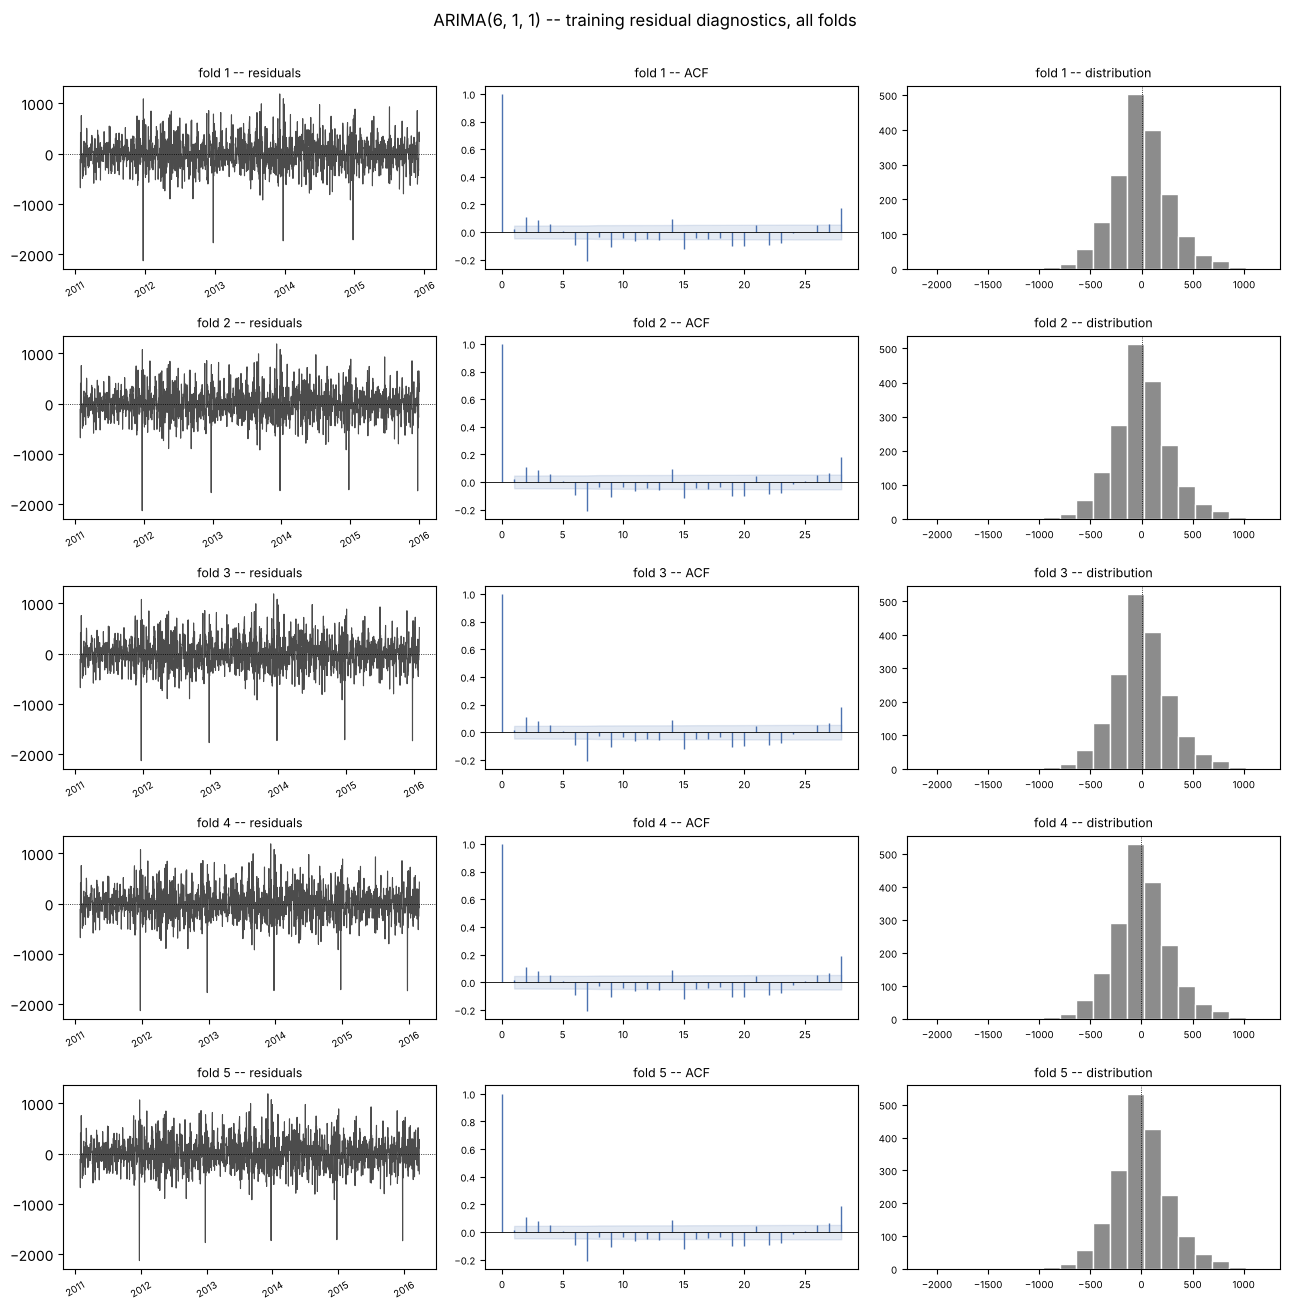

Saved: /home/claude/work/intermittent-retail-demand-forecasting/reports/phase2/residual_diagnostics_sarima.png


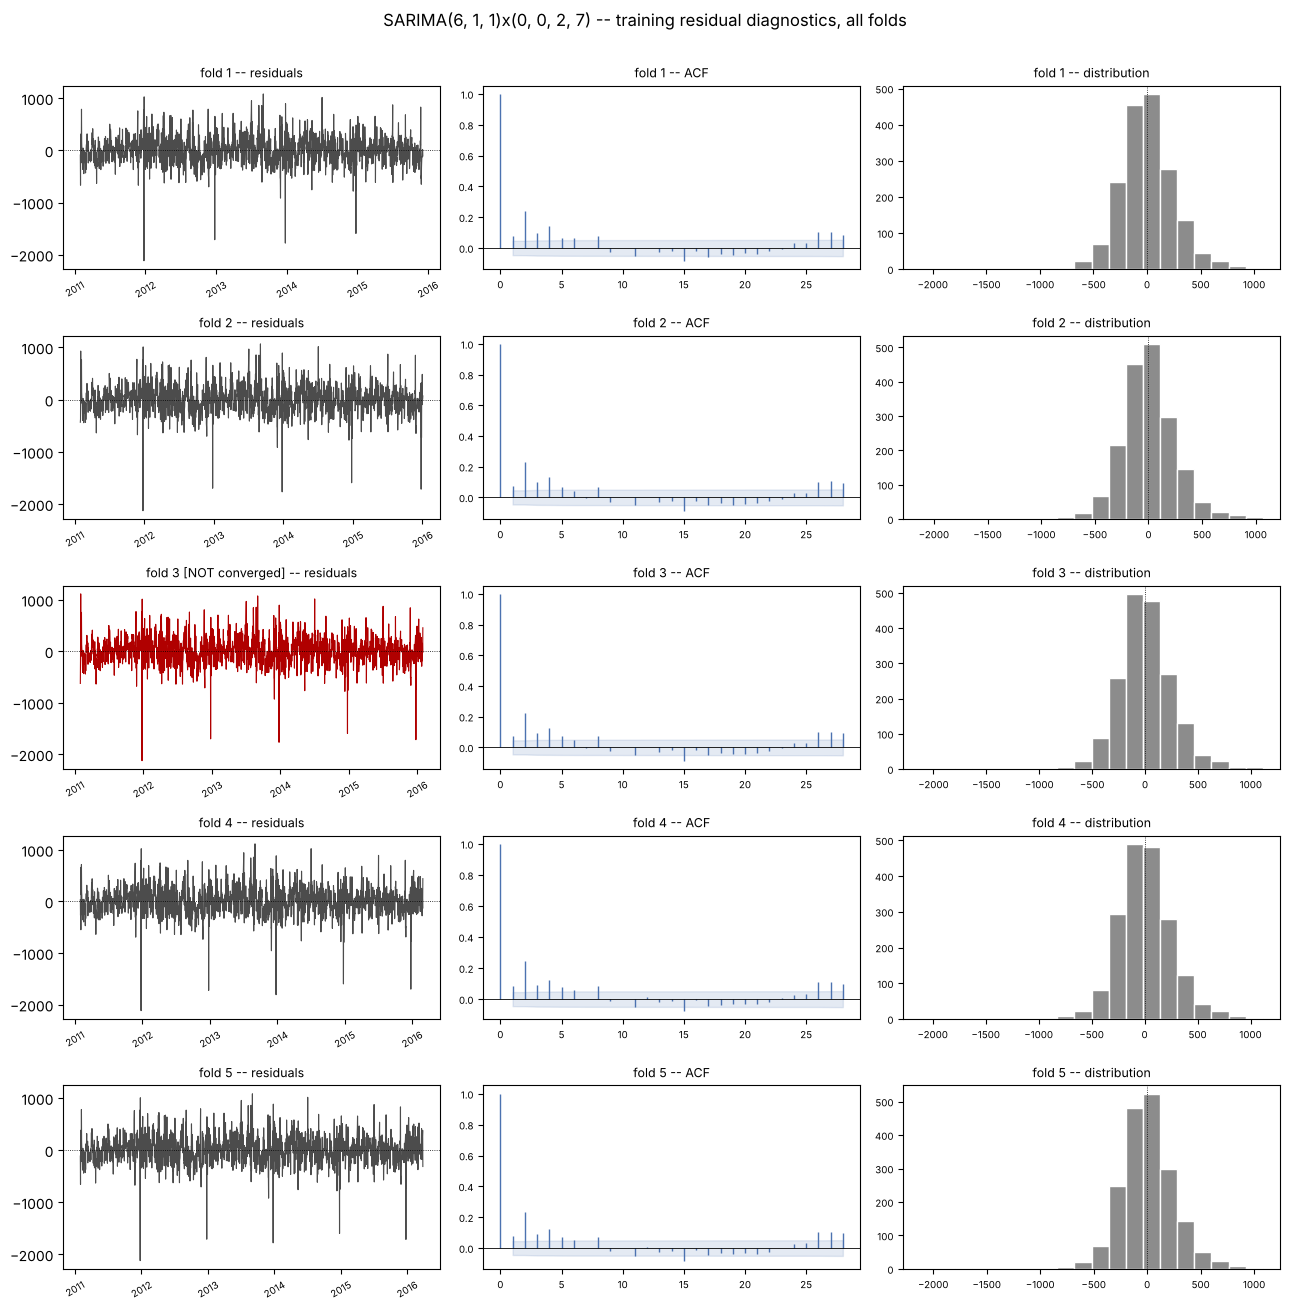

Saved: /home/claude/work/intermittent-retail-demand-forecasting/reports/phase2/residual_diagnostics_holt_winters_add.png


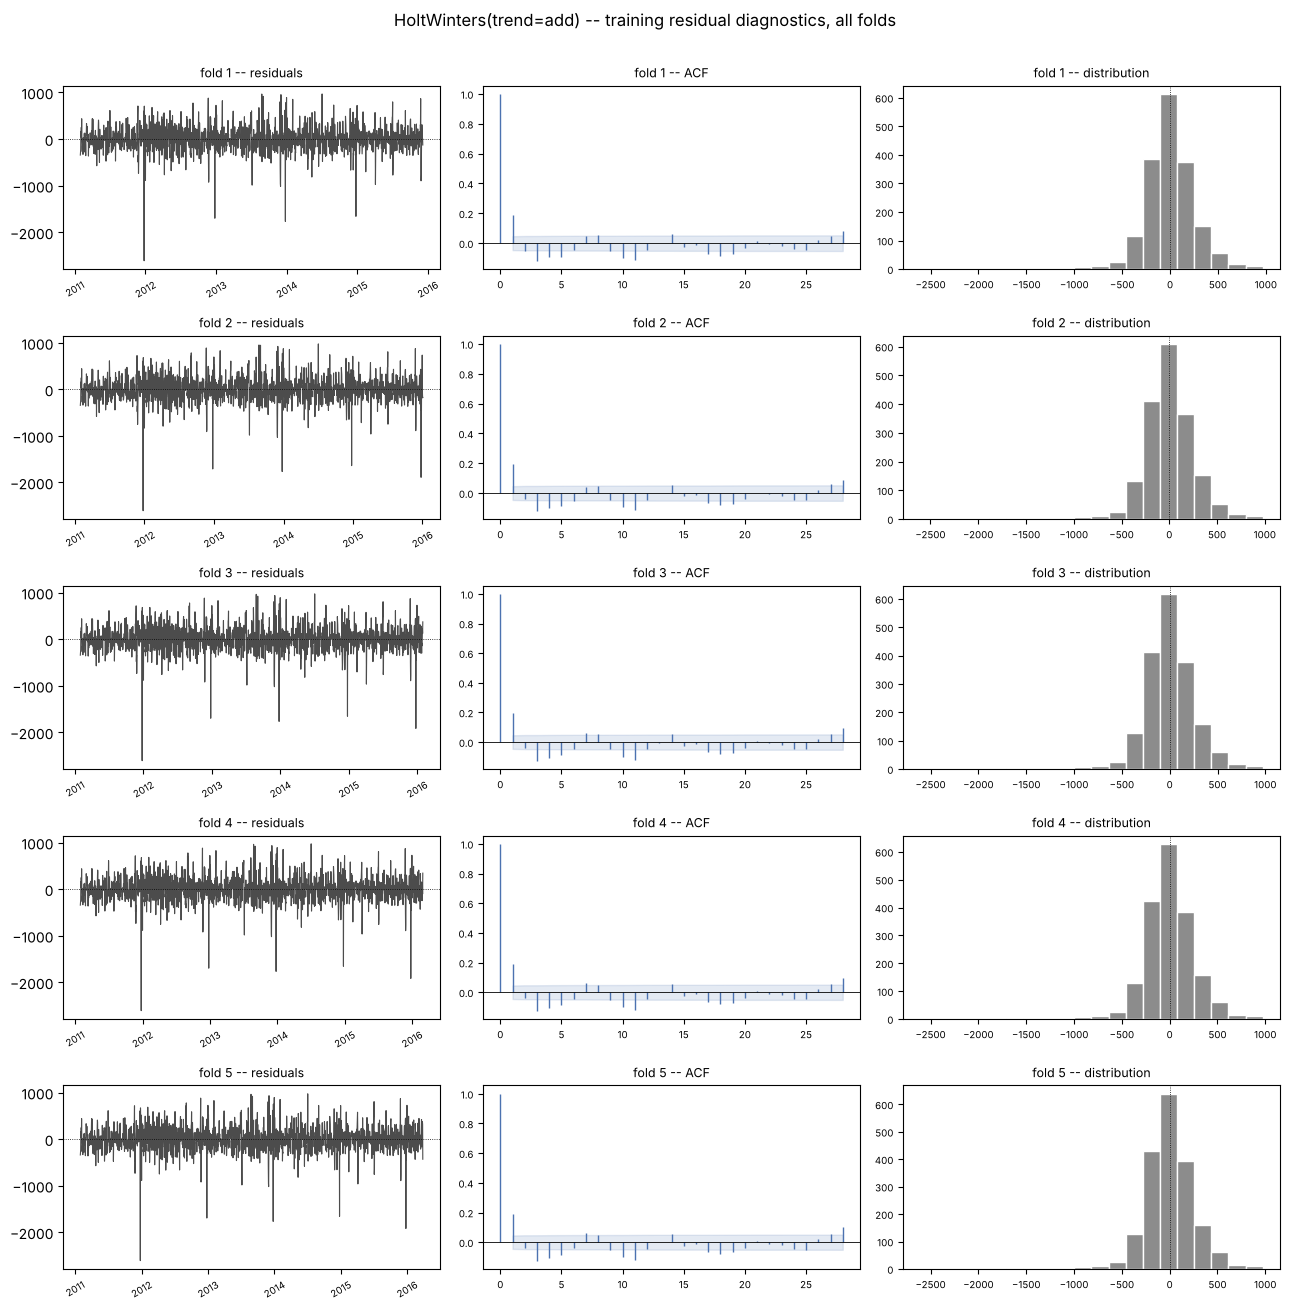

Saved: /home/claude/work/intermittent-retail-demand-forecasting/reports/phase2/residual_diagnostics_holt_winters_none.png


In [45]:
residual_plot_prefix = config["phase2"]["residual_diagnostics_plot_prefix"]
residual_plot_paths = {}

for label, diag_list in [
    ("arima", arima_diag), ("sarima", sarima_diag),
    ("holt_winters_add", hw_add_diag), ("holt_winters_none", hw_none_diag),
]:
    fig = plot_residual_diagnostics_grid(diag_list)
    path = reports_dir / f"{residual_plot_prefix}_{label}.png"
    fig.savefig(path, dpi=110, bbox_inches="tight")
    residual_plot_paths[label] = path
    print(f"Saved: {path}")
    plt.show()

### 11.5 Ljung-Box test results across all models and folds

**Null hypothesis (H0):** the residuals are independently distributed
(no remaining autocorrelation) up to the tested lag -- i.e. the fitted
model has already captured the series' linear autocorrelation structure
through that lag. Rejecting H0 (p-value below 0.05) is evidence
autocorrelation remains; failing to reject is consistent with, but does
not prove, residual white noise at that lag. Lag 7 is untestable for
every model in this project (reported as such, not as a misleading
"pass"): every model here has `model_df` >= 8, which leaves zero
degrees of freedom for the chi-square statistic at lag 7 once the
`model_df` parameter correction is applied.

No single lag, and no single model's full set of lags, is read as
proving that model adequate on its own -- see `MODEL_ADEQUACY_CAVEAT`,
printed again at the end of this subsection.

In [46]:
ljung_box_long = residual_diagnostics_table(all_diag)
ljung_box_path = metrics_dir / config["phase2"]["residual_ljung_box_filename"]
ljung_box_long.to_csv(ljung_box_path, index=False)
print(f"Saved: {ljung_box_path}\n")

# Reject-H0 rate by model and lag -- the real, computed pattern (not
# asserted in prose above), across every fold of every model.
testable = ljung_box_long.dropna(subset=["lb_pvalue"])
reject_rate = (
    testable.groupby(["model", "lag"])["reject_h0"]
    .apply(lambda s: f"{int(s.sum())}/{len(s)} folds reject H0")
    .unstack("lag")
)
reject_rate

Saved: /home/claude/work/intermittent-retail-demand-forecasting/artifacts/metrics/residual_diagnostics_ljung_box.csv



lag,14,21,28
model,,,
"ARIMA(6, 1, 1)",5/5 folds reject H0,5/5 folds reject H0,5/5 folds reject H0
HoltWinters(trend=add),5/5 folds reject H0,5/5 folds reject H0,5/5 folds reject H0
HoltWinters(trend=none),5/5 folds reject H0,5/5 folds reject H0,5/5 folds reject H0
"SARIMA(6, 1, 1)x(0, 0, 2, 7)",5/5 folds reject H0,5/5 folds reject H0,5/5 folds reject H0


In [47]:
print(MODEL_ADEQUACY_CAVEAT)

No single diagnostic here -- a residual plot, an ACF, a histogram, or one Ljung-Box lag -- proves a model is adequate on its own. A model can pass every in-sample residual check and still forecast poorly out-of-sample (and vice versa); this project's primary evidence for model quality remains the out-of-sample backtest MAE/RMSE from Phase 2 Steps 2 and 5, not the diagnostics below.


### 11.6 Holt-Winters trend-selection caveat

Section 7 (Phase 2 Step 5) already compared `trend="add"` against
`trend=None` by mean MAE/RMSE across the same 5 development folds and
set `DEFAULT_TREND` to the winner. Per the Step 6 brief, that comparison
is repeated here at **fold level** (not just the mean), side by side,
with the caveat stated explicitly: **selecting a model variant using
the same folds that variant is then evaluated on is model-selection
optimism** -- the reported MAE/RMSE for the chosen trend is not an
independent estimate of its out-of-sample accuracy, because the
selection step already used that same evidence. This is not resolved by
checking the final holdout (which would just move the same problem to a
new, now-no-longer-reserved-for-final-reporting sample) -- the final
holdout is not accessed anywhere in this cell or notebook for this or
any other purpose.

In [48]:
hw_fold_comparison = hw_add_summary[["fold", "forecast_start", "forecast_end", "MAE", "RMSE", "success"]].merge(
    hw_none_summary[["fold", "MAE", "RMSE", "success"]],
    on="fold", suffixes=("_trend_add", "_trend_none"),
)
hw_fold_comparison_path = metrics_dir / config["phase2"]["holt_winters_trend_selection_caveat_filename"]
hw_fold_comparison.to_csv(hw_fold_comparison_path, index=False)
print(f"Saved: {hw_fold_comparison_path}\n")
print("Holt-Winters trend=add vs trend=None, fold-by-fold (both development-fold only, never the holdout):")
print(hw_fold_comparison.to_string(index=False))

add_wins = int((hw_fold_comparison["MAE_trend_add"] < hw_fold_comparison["MAE_trend_none"]).sum())
none_wins = int((hw_fold_comparison["MAE_trend_none"] < hw_fold_comparison["MAE_trend_add"]).sum())
add_mae_mean = hw_add_summary["MAE"].mean()
none_mae_mean = hw_none_summary["MAE"].mean()
print(f"\ntrend=\"add\" has the lower MAE on {add_wins}/5 folds; trend=None on {none_wins}/5 folds.")
print(f"Mean MAE (already reported in Section 7): add={add_mae_mean:.2f}  none={none_mae_mean:.2f}")
print("\nCAVEAT: the trend variant used as \"the\" Holt-Winters model throughout this notebook "
      "(DEFAULT_TREND) was chosen using exactly these 5 folds. The MAE/RMSE reported for it in "
      "Sections 7-10 is therefore NOT an independent out-of-sample validation of that choice -- "
      "it is the same evidence the choice was made from. No holdout access was used to resolve "
      "this, by design (Step 6 instructions).")
print("\nFinal holdout accessed in this cell: False (split.test is not referenced above).")

Saved: /home/claude/work/intermittent-retail-demand-forecasting/artifacts/metrics/holt_winters_trend_selection_caveat.csv

Holt-Winters trend=add vs trend=None, fold-by-fold (both development-fold only, never the holdout):
 fold forecast_start forecast_end  MAE_trend_add  RMSE_trend_add  success_trend_add  MAE_trend_none  RMSE_trend_none  success_trend_none
    1     2015-12-07   2016-01-03     270.142772      426.717162               True      275.408940       429.961619                True
    2     2016-01-04   2016-01-31     249.620316      328.554662               True      250.120159       324.043126                True
    3     2016-02-01   2016-02-28     167.289138      207.382266               True      170.397209       209.562580                True
    4     2016-02-29   2016-03-27     143.487300      207.792623               True      141.398330       205.685500                True
    5     2016-03-28   2016-04-24     136.206089      161.742695               True      133

### 11.7 Section 11 summary

In [49]:
print("Phase 2 Step 6 summary -- residual diagnostics and classical-model validation:\n")

print("Folds diagnosed (training residuals, not forecast error):")
for label, diag_list in [("ARIMA", arima_diag), ("SARIMA", sarima_diag),
                          ("Holt-Winters (add)", hw_add_diag), ("Holt-Winters (none)", hw_none_diag)]:
    n_conv = sum(1 for d in diag_list if d.converged is not False)
    print(f"  {label:22s}: {len(diag_list)}/5 folds  ({n_conv}/{len(diag_list)} converged)")

print(f"\nSARIMA fold 3: converged={fold3_diag['converged']}  "
      "(see Section 11.3 for the full investigation and the separate sensitivity check)")

print(f"\nHolt-Winters trend selection: DEFAULT_TREND={DEFAULT_TREND!r}, chosen via the same 5 "
      "development folds it is evaluated on (Section 11.6 caveat -- model-selection optimism, "
      "not an independent validation).")

print(f"\n{MODEL_ADEQUACY_CAVEAT}")

print(f"\nFinal holdout ({split.test_start.date()} to {split.test_end.date()}): "
      "NOT used anywhere in Section 11 for residual computation, Ljung-Box testing, the SARIMA "
      "fold-3 investigation (original or sensitivity check), or the Holt-Winters trend caveat -- "
      "every diagnostic above was built only from development-fold backtest results "
      "(arima_results / sarima_results / hw_add_results / hw_none_results), which were "
      "themselves never fit on or evaluated against split.test.")

Phase 2 Step 6 summary -- residual diagnostics and classical-model validation:

Folds diagnosed (training residuals, not forecast error):
  ARIMA                 : 5/5 folds  (5/5 converged)
  SARIMA                : 5/5 folds  (4/5 converged)
  Holt-Winters (add)    : 5/5 folds  (5/5 converged)
  Holt-Winters (none)   : 5/5 folds  (5/5 converged)

SARIMA fold 3: converged=False  (see Section 11.3 for the full investigation and the separate sensitivity check)

Holt-Winters trend selection: DEFAULT_TREND='add', chosen via the same 5 development folds it is evaluated on (Section 11.6 caveat -- model-selection optimism, not an independent validation).

No single diagnostic here -- a residual plot, an ACF, a histogram, or one Ljung-Box lag -- proves a model is adequate on its own. A model can pass every in-sample residual check and still forecast poorly out-of-sample (and vice versa); this project's primary evidence for model quality remains the out-of-sample backtest MAE/RMSE from Phase 2

## 12. Item-Level Forecasting — Croston and TSB (Phase 2 Step 7)

Sections 1-11 above modeled a single series: the CA_1/FOODS_3 **daily
aggregate** (summed across the full ~823-item catalog). This section
moves to **item-level** forecasting: the 20 representative products
selected in Phase 1 (5 each of Smooth / Intermittent / Erratic / Lumpy,
via the ADI/CV² thresholds already approved in
`data/processed/selected_items.parquet`), comparing a per-item Seasonal
Naive baseline against two intermittent-demand-specific methods,
Croston's method and TSB (Teunter-Syntetos-Babai 2011), neither of
which has appeared anywhere above.

**What's new vs. reused.** `src/models/croston.py` and
`src/models/tsb.py` are new (Section 12.2) -- manual implementations,
no external intermittent-demand library. Everything else is the exact
same, already-approved machinery every prior Phase 2 step used, called
once per item instead of once for the aggregate series:
`src.data.splitter.split_final_holdout`, `src.evaluation.backtesting`'s
`run_backtest` / `summarize_backtest`, and `src.evaluation.metrics`'s
MAE / RMSE / zero-protected-MAPE are all unmodified. The only new
orchestration code is `src.evaluation.item_level`, which loops the
unmodified `run_backtest` over 20 items x 3 models and adds the
macro-averaged-by-category summary the Step 7 brief asks for.

**Error-scale caveat -- read this before comparing any number below to
Sections 1-11.** A single item's daily sales are a small fraction of
the full-catalog aggregate, so item-level MAE/RMSE are structurally far
smaller than the aggregate-series MAE/RMSE reported above just from
scale -- **not** because any item-level model is "more accurate" than
ARIMA/SARIMA/Holt-Winters on the aggregate. Nothing in this section
compares the two.

**Final holdout.** Same boundary as every section above (`2016-04-25`
to `2016-05-22`), carved off per item by the same `split_final_holdout`
call Section 3 used on the aggregate series. Section 12.4 below
confirms explicitly that no date on or after `2016-04-25` was used
anywhere in this section.

### 12.1 Setup and data load

New imports for this section only (Sections 1-11's own imports in cell
2 are untouched). Loads
`data/processed/selected_items_daily_sales.parquet` -- built for this
step from the real, uploaded CA_1/FOODS_3 panel, filtered to these 20
item_ids and joined against the approved `selected_items.parquet`
(never fabricated or reconstructed) -- and confirms its shape against
the brief's expectation before anything else runs.

In [50]:
from src.evaluation.item_level import (
    category_macro_average_summary,
    per_item_summary,
    plot_category_comparison,
    plot_example_item_forecasts,
    run_item_level_backtests,
)
from src.models.croston import CrostonForecaster
from src.models.tsb import TSBForecaster

daily_sales_path = processed_dir / config["output"]["selected_items_daily_sales_filename"]
if not daily_sales_path.exists():
    raise FileNotFoundError(
        f"'{daily_sales_path}' not found. Build it from the real CA_1/FOODS_3 panel first."
    )

daily_sales = pd.read_parquet(daily_sales_path)
daily_sales["date"] = pd.to_datetime(daily_sales["date"])

item_ids = sorted(daily_sales["item_id"].unique())
assert len(item_ids) == 20, f"Expected 20 selected items, got {len(item_ids)}"
assert len(daily_sales) == 20 * 1941, f"Expected 38820 rows, got {len(daily_sales)}"

print(f"Loaded {daily_sales_path}")
print(f"{len(daily_sales)} rows, {len(item_ids)} items, "
      f"{daily_sales['date'].min().date()} to {daily_sales['date'].max().date()}")
print("\nItems per demand class:")
print(daily_sales.drop_duplicates("item_id")["demand_class"].value_counts())
daily_sales.head(3)

Loaded /home/claude/work/intermittent-retail-demand-forecasting/data/processed/selected_items_daily_sales.parquet
38820 rows, 20 items, 2011-01-29 to 2016-05-22

Items per demand class:
demand_class
Lumpy           5
Intermittent    5
Smooth          5
Erratic         5
Name: count, dtype: int64


,item_id,date,sales,demand_class
0,FOODS_3_024,2011-01-29,0,Lumpy
1,FOODS_3_024,2011-01-30,0,Lumpy
2,FOODS_3_024,2011-01-31,0,Lumpy


### 12.2 Croston and TSB — method summary and fixed parameters

**Croston (1972), classic, non-bias-corrected.** Exponentially smooths
the demand **size** and the **interval** (in periods) between
occurrences separately, both with one fixed `alpha`
(`config["models"]["croston_alpha"]`). Forecast =
smoothed_size / smoothed_interval, held flat across the whole horizon.
Leading zeros are never special-cased -- they are simply counted as
elapsed periods, so they're naturally absorbed into the first interval
estimate. An all-zero training window gives Croston no occurrence at
all to compute a ratio from, so `fit()` raises `ValueError` rather than
inventing a 0/0 forecast.

**TSB (Teunter-Syntetos-Babai 2011).** Smooths an **occurrence
probability** every period (including zero-demand ones) with `alpha`,
and the demand **size** only on occurrence periods with `beta`
(`config["models"]["tsb_alpha"]` / `["tsb_beta"]`). Forecast =
smoothed_probability x smoothed_size, also held flat. Both smoothed
states are seeded at exactly `0.0`; on an all-zero training window
neither state is ever updated away from `0.0`, so the forecast is a
well-defined `0.0` -- TSB degrades gracefully in exactly the situation
where Croston raises. That's a genuine difference in the two methods'
update rules, not an inconsistency between these two wrappers.

Both forecasts are **flat lines** by construction -- neither method
models a day-by-day shape within the horizon, unlike Seasonal Naive's
repeating weekly pattern or ARIMA/SARIMA/Holt-Winters' fitted dynamics.
The demo below fits both on one example item and prints their raw
`fit_diagnostics()`.

In [51]:
demo_item = daily_sales.loc[daily_sales["demand_class"] == "Smooth", "item_id"].iloc[0]
demo_series = (
    daily_sales.loc[daily_sales["item_id"] == demo_item]
    .sort_values("date")
    .set_index("date")["sales"]
)
demo_croston = CrostonForecaster(alpha=config["models"]["croston_alpha"]).fit(demo_series)
demo_tsb = TSBForecaster(alpha=config["models"]["tsb_alpha"], beta=config["models"]["tsb_beta"]).fit(demo_series)

print(f"Demo item (Smooth category): {demo_item}, {len(demo_series)} obs")
print("\nCroston fit_diagnostics():")
for k, v in demo_croston.fit_diagnostics().items():
    print(f"  {k}: {v}")
print("\nTSB fit_diagnostics():")
for k, v in demo_tsb.fit_diagnostics().items():
    print(f"  {k}: {v}")

Demo item (Smooth category): FOODS_3_067, 1941 obs

Croston fit_diagnostics():
  alpha: 0.1
  n_obs_fit: 1941
  n_occurrences: 1599
  demand_size_smoothed: 3.7737422911010956
  interval_smoothed: 1.0196337386593495
  forecast_value: 3.701076325762764

TSB fit_diagnostics():
  alpha: 0.1
  beta: 0.1
  n_obs_fit: 1941
  n_occurrences: 1599
  probability_smoothed: 0.9866464442243507
  demand_size_smoothed: 3.7737422911010956
  forecast_value: 3.7233494129339504


### 12.3 Run the item-level backtest

20 items x {Seasonal Naive (`season_length=7`), Croston, TSB} x 5
expanding development folds x 28-day horizon -- the same fold layout
(same `backtest.horizon` / `backtest.n_folds`) every prior section
used, via the unmodified `run_backtest` per (item, model) pair. Each
item's development series is carved from its own holdout-excluded rows
by `src.evaluation.item_level.item_development_series`, which calls the
same `split_final_holdout` Section 3 used on the aggregate series.

In [52]:
model_factories = {
    "SeasonalNaive": lambda: SeasonalNaive(season_length=config["backtest"]["season_length"]),
    "Croston": lambda: CrostonForecaster(alpha=config["models"]["croston_alpha"]),
    "TSB": lambda: TSBForecaster(alpha=config["models"]["tsb_alpha"], beta=config["models"]["tsb_beta"]),
}

item_level_results = run_item_level_backtests(
    daily_sales,
    item_ids,
    model_factories,
    horizon=config["backtest"]["horizon"],
    n_folds=config["backtest"]["n_folds"],
    holdout_days=config["backtest"]["holdout_days"],
)
item_level_long = item_level_results["long"]
item_level_fold_summary = item_level_results["fold_summary"]

n_expected_long = len(item_ids) * len(model_factories) * config["backtest"]["n_folds"] * config["backtest"]["horizon"]
n_expected_folds = len(item_ids) * len(model_factories) * config["backtest"]["n_folds"]
print(f"Long results table: {len(item_level_long)} rows (expected {n_expected_long})")
print(f"Fold summary table: {len(item_level_fold_summary)} rows (expected {n_expected_folds})")
assert len(item_level_long) == n_expected_long
assert len(item_level_fold_summary) == n_expected_folds

n_failed = int((~item_level_fold_summary["success"]).sum())
print(f"Failed (item, model, fold) combinations: {n_failed}")
if n_failed:
    print(item_level_fold_summary.loc[
        ~item_level_fold_summary["success"],
        ["item_id", "demand_class", "model", "fold", "error"],
    ].to_string(index=False))

2026-10-12 03:33:22 | INFO     | src.data.splitter | Final holdout split:
development: 2011-01-29 -> 2016-04-24 (1913 days)
final test:  2016-04-25 -> 2016-05-22 (28 days)


2026-10-12 03:33:22 | INFO     | src.evaluation.item_level | Item FOODS_3_024 (Lumpy): development series 1913 obs, 2011-01-29 to 2016-04-24


2026-10-12 03:33:22 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:22 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:22 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:22 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:22 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:22 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:22 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:22 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:22 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:22 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:22 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:22 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:22 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:22 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:22 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:22 | INFO     | src.data.splitter | Final holdout split:
development: 2011-01-29 -> 2016-04-24 (1913 days)
final test:  2016-04-25 -> 2016-05-22 (28 days)


2026-10-12 03:33:22 | INFO     | src.evaluation.item_level | Item FOODS_3_042 (Intermittent): development series 1913 obs, 2011-01-29 to 2016-04-24


2026-10-12 03:33:22 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:22 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:22 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:22 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:22 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:22 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:22 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:22 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.data.splitter | Final holdout split:
development: 2011-01-29 -> 2016-04-24 (1913 days)
final test:  2016-04-25 -> 2016-05-22 (28 days)


2026-10-12 03:33:23 | INFO     | src.evaluation.item_level | Item FOODS_3_067 (Smooth): development series 1913 obs, 2011-01-29 to 2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.data.splitter | Final holdout split:
development: 2011-01-29 -> 2016-04-24 (1913 days)
final test:  2016-04-25 -> 2016-05-22 (28 days)


2026-10-12 03:33:23 | INFO     | src.evaluation.item_level | Item FOODS_3_076 (Erratic): development series 1913 obs, 2011-01-29 to 2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.data.splitter | Final holdout split:
development: 2011-01-29 -> 2016-04-24 (1913 days)
final test:  2016-04-25 -> 2016-05-22 (28 days)


2026-10-12 03:33:23 | INFO     | src.evaluation.item_level | Item FOODS_3_206 (Intermittent): development series 1913 obs, 2011-01-29 to 2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.data.splitter | Final holdout split:
development: 2011-01-29 -> 2016-04-24 (1913 days)
final test:  2016-04-25 -> 2016-05-22 (28 days)


2026-10-12 03:33:23 | INFO     | src.evaluation.item_level | Item FOODS_3_230 (Smooth): development series 1913 obs, 2011-01-29 to 2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.data.splitter | Final holdout split:
development: 2011-01-29 -> 2016-04-24 (1913 days)
final test:  2016-04-25 -> 2016-05-22 (28 days)


2026-10-12 03:33:23 | INFO     | src.evaluation.item_level | Item FOODS_3_263 (Smooth): development series 1913 obs, 2011-01-29 to 2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.data.splitter | Final holdout split:
development: 2011-01-29 -> 2016-04-24 (1913 days)
final test:  2016-04-25 -> 2016-05-22 (28 days)


2026-10-12 03:33:23 | INFO     | src.evaluation.item_level | Item FOODS_3_264 (Intermittent): development series 1913 obs, 2011-01-29 to 2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.data.splitter | Final holdout split:
development: 2011-01-29 -> 2016-04-24 (1913 days)
final test:  2016-04-25 -> 2016-05-22 (28 days)


2026-10-12 03:33:23 | INFO     | src.evaluation.item_level | Item FOODS_3_271 (Lumpy): development series 1913 obs, 2011-01-29 to 2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.data.splitter | Final holdout split:
development: 2011-01-29 -> 2016-04-24 (1913 days)
final test:  2016-04-25 -> 2016-05-22 (28 days)


2026-10-12 03:33:23 | INFO     | src.evaluation.item_level | Item FOODS_3_313 (Erratic): development series 1913 obs, 2011-01-29 to 2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.data.splitter | Final holdout split:
development: 2011-01-29 -> 2016-04-24 (1913 days)
final test:  2016-04-25 -> 2016-05-22 (28 days)


2026-10-12 03:33:23 | INFO     | src.evaluation.item_level | Item FOODS_3_319 (Erratic): development series 1913 obs, 2011-01-29 to 2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.data.splitter | Final holdout split:
development: 2011-01-29 -> 2016-04-24 (1913 days)
final test:  2016-04-25 -> 2016-05-22 (28 days)


2026-10-12 03:33:23 | INFO     | src.evaluation.item_level | Item FOODS_3_330 (Smooth): development series 1913 obs, 2011-01-29 to 2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.data.splitter | Final holdout split:
development: 2011-01-29 -> 2016-04-24 (1913 days)
final test:  2016-04-25 -> 2016-05-22 (28 days)


2026-10-12 03:33:23 | INFO     | src.evaluation.item_level | Item FOODS_3_341 (Intermittent): development series 1913 obs, 2011-01-29 to 2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.data.splitter | Final holdout split:
development: 2011-01-29 -> 2016-04-24 (1913 days)
final test:  2016-04-25 -> 2016-05-22 (28 days)


2026-10-12 03:33:23 | INFO     | src.evaluation.item_level | Item FOODS_3_348 (Smooth): development series 1913 obs, 2011-01-29 to 2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.data.splitter | Final holdout split:
development: 2011-01-29 -> 2016-04-24 (1913 days)
final test:  2016-04-25 -> 2016-05-22 (28 days)


2026-10-12 03:33:23 | INFO     | src.evaluation.item_level | Item FOODS_3_404 (Erratic): development series 1913 obs, 2011-01-29 to 2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.data.splitter | Final holdout split:
development: 2011-01-29 -> 2016-04-24 (1913 days)
final test:  2016-04-25 -> 2016-05-22 (28 days)


2026-10-12 03:33:23 | INFO     | src.evaluation.item_level | Item FOODS_3_422 (Lumpy): development series 1913 obs, 2011-01-29 to 2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.data.splitter | Final holdout split:
development: 2011-01-29 -> 2016-04-24 (1913 days)
final test:  2016-04-25 -> 2016-05-22 (28 days)


2026-10-12 03:33:23 | INFO     | src.evaluation.item_level | Item FOODS_3_672 (Lumpy): development series 1913 obs, 2011-01-29 to 2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.data.splitter | Final holdout split:
development: 2011-01-29 -> 2016-04-24 (1913 days)
final test:  2016-04-25 -> 2016-05-22 (28 days)


2026-10-12 03:33:23 | INFO     | src.evaluation.item_level | Item FOODS_3_702 (Erratic): development series 1913 obs, 2011-01-29 to 2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.data.splitter | Final holdout split:
development: 2011-01-29 -> 2016-04-24 (1913 days)
final test:  2016-04-25 -> 2016-05-22 (28 days)


2026-10-12 03:33:23 | INFO     | src.evaluation.item_level | Item FOODS_3_761 (Lumpy): development series 1913 obs, 2011-01-29 to 2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.data.splitter | Final holdout split:
development: 2011-01-29 -> 2016-04-24 (1913 days)
final test:  2016-04-25 -> 2016-05-22 (28 days)


2026-10-12 03:33:23 | INFO     | src.evaluation.item_level | Item FOODS_3_780 (Intermittent): development series 1913 obs, 2011-01-29 to 2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [SeasonalNaive] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [Croston(alpha=0.1)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 1: origin=2015-12-06 forecast=2015-12-07..2016-01-03


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 2: origin=2016-01-03 forecast=2016-01-04..2016-01-31


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 3: origin=2016-01-31 forecast=2016-02-01..2016-02-28


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 4: origin=2016-02-28 forecast=2016-02-29..2016-03-27


2026-10-12 03:33:23 | INFO     | src.evaluation.backtesting | [TSB(alpha=0.1,beta=0.1)] fold 5: origin=2016-03-27 forecast=2016-03-28..2016-04-24


Long results table: 8400 rows (expected 8400)
Fold summary table: 300 rows (expected 300)
Failed (item, model, fold) combinations: 0


### 12.4 Final-holdout leakage check

In [53]:
max_date_long = pd.to_datetime(item_level_long["date"]).max()
max_forecast_end = pd.to_datetime(item_level_fold_summary["forecast_end"]).max()

print(f"Final holdout starts: {split.test_start.date()} (from Section 3's split, not retyped here)")
print(f"Latest date used anywhere in Section 12's long results table: {max_date_long.date()}")
print(f"Latest forecast_end anywhere in Section 12's fold summary: {max_forecast_end.date()}")

assert max_date_long < split.test_start, "HOLDOUT LEAKAGE in item-level long results table!"
assert max_forecast_end < split.test_start, "HOLDOUT LEAKAGE in item-level fold summary!"
print("\nConfirmed: no date on or after the final holdout start was used anywhere in Section 12.")

Final holdout starts: 2016-04-25 (from Section 3's split, not retyped here)
Latest date used anywhere in Section 12's long results table: 2016-04-24
Latest forecast_end anywhere in Section 12's fold summary: 2016-04-24

Confirmed: no date on or after the final holdout start was used anywhere in Section 12.


### 12.5 Per-item results

Mean MAE / RMSE / zero-protected-MAPE per item per model, averaged
across that item's 5 folds (successful folds only; `MAPE_n_folds_valid`
is how many of those 5 folds had at least one non-zero actual in their
28-day test window -- MAPE is undefined on the rest, per the same
zero-actual exclusion `src.evaluation.metrics.mape` has used
everywhere above).

In [54]:
item_level_per_item_summary = per_item_summary(item_level_fold_summary)
item_level_per_item_summary = item_level_per_item_summary.sort_values(
    ["demand_class", "item_id", "model"]
).reset_index(drop=True)
item_level_per_item_summary

,item_id,demand_class,model,n_folds,n_success,MAE_mean,RMSE_mean,MAPE_mean,MAPE_n_folds_valid
0,FOODS_3_076,Erratic,Croston(alpha=0.1),5,5,1.903868,2.344998,68.816941,5
1,FOODS_3_076,Erratic,SeasonalNaive,5,5,2.250000,2.883073,73.134062,5
2,FOODS_3_076,Erratic,"TSB(alpha=0.1,beta=0.1)",5,5,1.903083,2.341471,68.958938,5
3,FOODS_3_313,Erratic,Croston(alpha=0.1),5,5,2.311127,2.828970,59.795272,5
4,FOODS_3_313,Erratic,SeasonalNaive,5,5,2.842857,3.564954,60.281927,5
5,FOODS_3_313,Erratic,"TSB(alpha=0.1,beta=0.1)",5,5,2.313617,2.830103,59.898044,5
6,FOODS_3_319,Erratic,Croston(alpha=0.1),5,5,6.226042,7.275151,69.395792,5
7,FOODS_3_319,Erratic,SeasonalNaive,5,5,5.871429,7.440189,86.729989,5
8,FOODS_3_319,Erratic,"TSB(alpha=0.1,beta=0.1)",5,5,5.107369,6.584714,82.215166,5
9,FOODS_3_404,Erratic,Croston(alpha=0.1),5,5,7.988451,8.736059,107.942331,5


### 12.6 Category-level comparison (macro-averaged across items)

Per the Step 7 brief: summarized by **macro-average** -- the unweighted
mean of each item's own mean error, across the 5 items in a category --
so a high-volume item cannot dominate a category's number the way a
pooled/volume-weighted average would let it. `n_items` confirms all 5
items per category contributed.

In [55]:
category_order = ["Smooth", "Intermittent", "Erratic", "Lumpy"]

item_level_category_summary = category_macro_average_summary(item_level_per_item_summary)
item_level_category_summary["demand_class"] = pd.Categorical(
    item_level_category_summary["demand_class"], categories=category_order, ordered=True
)
item_level_category_summary = item_level_category_summary.sort_values(
    ["demand_class", "model"]
).reset_index(drop=True)
item_level_category_summary

,demand_class,model,n_items,MAE_macro_mean,RMSE_macro_mean,MAPE_macro_mean,MAPE_n_items_valid
0,Smooth,Croston(alpha=0.1),5,2.503643,3.217453,64.835879,5
1,Smooth,SeasonalNaive,5,2.940000,3.872492,87.267661,5
2,Smooth,"TSB(alpha=0.1,beta=0.1)",5,2.297595,3.035113,67.613010,5
3,Intermittent,Croston(alpha=0.1),5,1.031868,1.318320,58.047343,5
4,Intermittent,SeasonalNaive,5,1.102857,1.549040,77.801136,5
5,Intermittent,"TSB(alpha=0.1,beta=0.1)",5,0.945628,1.222705,51.700409,5
6,Erratic,Croston(alpha=0.1),5,4.389906,5.105560,71.400274,5
7,Erratic,SeasonalNaive,5,4.038571,5.116972,78.122741,5
8,Erratic,"TSB(alpha=0.1,beta=0.1)",5,3.387548,4.263232,67.832931,5
9,Lumpy,Croston(alpha=0.1),5,1.594086,1.862436,65.244957,5


### 12.7 Does Croston or TSB beat the item-level Seasonal Naive baseline?

By category, on macro-averaged MAE -- mirroring Section 9's "does each
model beat Seasonal Naive" comparison, at item level instead of
aggregate level. The Step 7 brief is explicit that no universal winner
should be declared; the table below is read as-is, category by
category, not reduced to one verdict.

In [56]:
pivot_mae = item_level_category_summary.pivot(index="demand_class", columns="model", values="MAE_macro_mean")
pivot_mae = pivot_mae.reindex(category_order)
print("Macro-averaged MAE by category and model:")
print(pivot_mae.to_string())
print()

for cat in category_order:
    if cat not in pivot_mae.index or pivot_mae.loc[cat].isna().all():
        continue
    row = pivot_mae.loc[cat]
    baseline = row.get("SeasonalNaive")
    for model_label in ["Croston", "TSB"]:
        if model_label in row.index and pd.notna(row[model_label]) and pd.notna(baseline):
            beats = row[model_label] < baseline
            pct = (baseline - row[model_label]) / baseline * 100
            verdict = "BEATS" if beats else "does NOT beat"
            print(f"{cat:13s} {model_label:8s} MAE={row[model_label]:7.4f}  "
                  f"vs SeasonalNaive MAE={baseline:7.4f}  -> {verdict} baseline ({pct:+.1f}%)")

Macro-averaged MAE by category and model:
model         Croston(alpha=0.1)  SeasonalNaive  TSB(alpha=0.1,beta=0.1)
demand_class                                                            
Smooth                  2.503643       2.940000                 2.297595
Intermittent            1.031868       1.102857                 0.945628
Erratic                 4.389906       4.038571                 3.387548
Lumpy                   1.594086       1.288571                 1.185365



### 12.8 Comparison plots

Two category-level bar charts (macro-averaged MAE, then RMSE), plus a
small-multiples actual-vs-predicted plot for one example item per
category at the final fold -- a visual complement to the bar charts,
showing Croston's and TSB's flat-line forecasts against Seasonal
Naive's repeating weekly shape and the real, often noisy actual
series.

Saved /home/claude/work/intermittent-retail-demand-forecasting/reports/phase2/item_level_category_mae_comparison.png


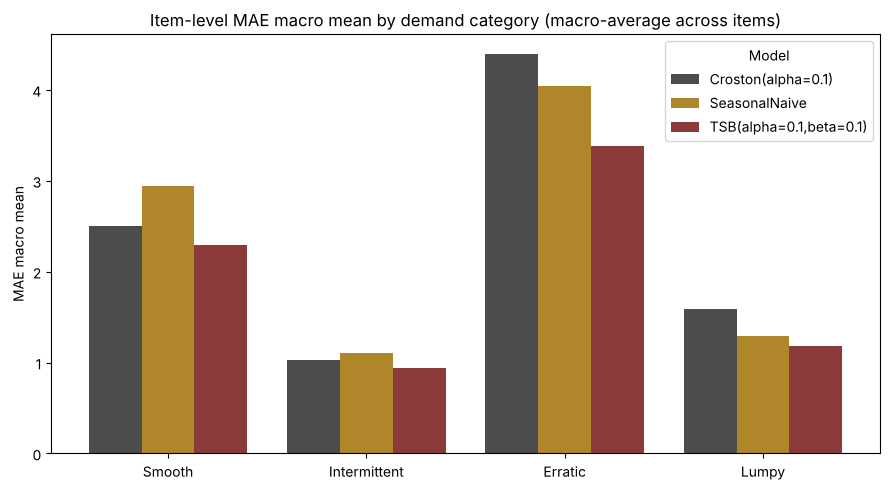

In [57]:
mae_plot_path = reports_dir / config["phase2"]["item_level_category_mae_plot_filename"]
ax = plot_category_comparison(item_level_category_summary, metric="MAE_macro_mean")
ax.figure.savefig(mae_plot_path, dpi=150)
print(f"Saved {mae_plot_path}")
plt.show()

Saved /home/claude/work/intermittent-retail-demand-forecasting/reports/phase2/item_level_category_rmse_comparison.png


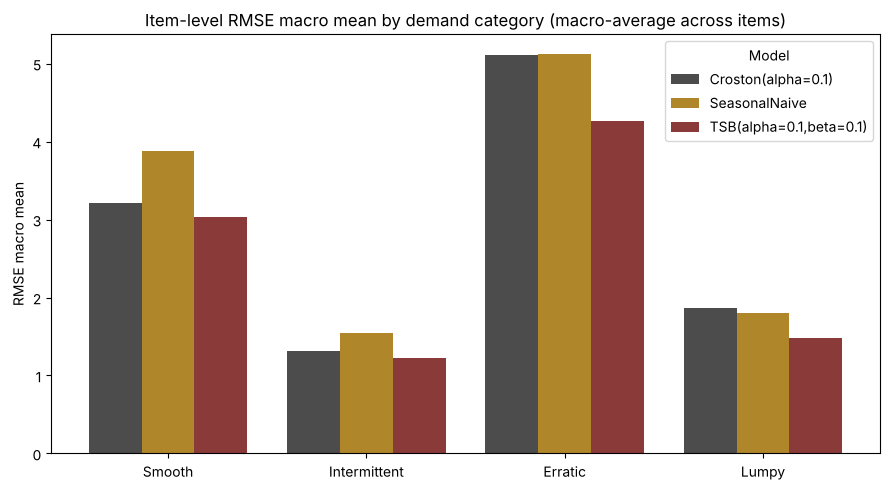

In [58]:
rmse_plot_path = reports_dir / config["phase2"]["item_level_category_rmse_plot_filename"]
ax = plot_category_comparison(item_level_category_summary, metric="RMSE_macro_mean")
ax.figure.savefig(rmse_plot_path, dpi=150)
print(f"Saved {rmse_plot_path}")
plt.show()

In [59]:
example_items = (
    daily_sales.sort_values("item_id")
    .groupby("demand_class", observed=True)["item_id"]
    .first()
    .reindex(category_order)
    .tolist()
)
print("Example items (one per category):", example_items)

example_plot_path = reports_dir / config["phase2"]["item_level_example_forecasts_plot_filename"]
example_fig = plot_example_item_forecasts(item_level_long, example_items, fold=config["backtest"]["n_folds"])
example_fig.savefig(example_plot_path, dpi=150)
print(f"Saved {example_plot_path}")
plt.show()

Example items (one per category): ['FOODS_3_067', 'FOODS_3_042', 'FOODS_3_076', 'FOODS_3_024']


Saved /home/claude/work/intermittent-retail-demand-forecasting/reports/phase2/item_level_example_forecasts.png


### 12.9 Save outputs

In [60]:
item_level_long_path = forecasts_dir / config["phase2"]["item_level_long_results_filename"]
item_level_long.to_csv(item_level_long_path, index=False)

item_level_fold_summary_path = metrics_dir / config["phase2"]["item_level_fold_summary_filename"]
item_level_fold_summary.to_csv(item_level_fold_summary_path, index=False)

item_level_per_item_summary_path = metrics_dir / config["phase2"]["item_level_per_item_summary_filename"]
item_level_per_item_summary.to_csv(item_level_per_item_summary_path, index=False)

item_level_category_summary_path = metrics_dir / config["phase2"]["item_level_category_summary_filename"]
item_level_category_summary.to_csv(item_level_category_summary_path, index=False)

for label, path in [
    ("long results", item_level_long_path),
    ("fold summary", item_level_fold_summary_path),
    ("per-item summary", item_level_per_item_summary_path),
    ("category summary", item_level_category_summary_path),
]:
    print(f"Saved {label} to {path} ({path.stat().st_size:,} bytes)")

Saved long results to /home/claude/work/intermittent-retail-demand-forecasting/artifacts/forecasts/item_level_backtest_long.csv (647,475 bytes)
Saved fold summary to /home/claude/work/intermittent-retail-demand-forecasting/artifacts/metrics/item_level_backtest_fold_summary.csv (38,378 bytes)
Saved per-item summary to /home/claude/work/intermittent-retail-demand-forecasting/artifacts/metrics/item_level_per_item_summary.csv (6,094 bytes)
Saved category summary to /home/claude/work/intermittent-retail-demand-forecasting/artifacts/metrics/item_level_category_macro_avg_summary.csv (1,129 bytes)


### 12.10 Section 12 summary

In [61]:
print("Phase 2 Step 7 summary -- item-level Croston / TSB vs. per-item Seasonal Naive:\n")
print(f"Items evaluated: {len(item_ids)} (5 each of Smooth / Intermittent / Erratic / Lumpy)")
print(f"Models: {list(model_factories.keys())}")
print(f"Folds per (item, model): {config['backtest']['n_folds']}, horizon: {config['backtest']['horizon']} days")
print(f"Total (item, model, fold) combinations: {len(item_level_fold_summary)}, "
      f"failed: {int((~item_level_fold_summary['success']).sum())}")

print("\nMacro-averaged MAE / RMSE by category and model:")
print(item_level_category_summary[[
    "demand_class", "model", "n_items", "MAE_macro_mean", "RMSE_macro_mean",
    "MAPE_macro_mean", "MAPE_n_items_valid",
]].to_string(index=False))

print(
    "\nNo single model wins in every category above (see 12.7) -- this section does not "
    "declare a universal winning model, per the Step 7 brief."
)
print(
    "\nItem-level MAE/RMSE above are NOT on the same scale as the aggregate-series MAE/RMSE "
    "reported in Sections 1-11 (see Section 12's intro) and must not be compared to them directly."
)
print(
    f"\nFinal holdout ({split.test_start.date()} to {split.test_end.date()}) was NOT used "
    "anywhere in this section -- confirmed explicitly in 12.4."
)

Phase 2 Step 7 summary -- item-level Croston / TSB vs. per-item Seasonal Naive:

Items evaluated: 20 (5 each of Smooth / Intermittent / Erratic / Lumpy)
Models: ['SeasonalNaive', 'Croston', 'TSB']
Folds per (item, model): 5, horizon: 28 days
Total (item, model, fold) combinations: 300, failed: 0

Macro-averaged MAE / RMSE by category and model:
demand_class                   model  n_items  MAE_macro_mean  RMSE_macro_mean  MAPE_macro_mean  MAPE_n_items_valid
      Smooth      Croston(alpha=0.1)        5        2.503643         3.217453        64.835879                   5
      Smooth           SeasonalNaive        5        2.940000         3.872492        87.267661                   5
      Smooth TSB(alpha=0.1,beta=0.1)        5        2.297595         3.035113        67.613010                   5
Intermittent      Croston(alpha=0.1)        5        1.031868         1.318320        58.047343                   5
Intermittent           SeasonalNaive        5        1.102857         1.5

## Next step — NOT YET IMPLEMENTED

ARIMA, SARIMA, and Holt-Winters are implemented, fit, and backtested in
sections 5-10 (Phase 2 Step 5) -- Seasonal Naive (now folded into
section "5. Seasonal Naive baseline") is unchanged from Phase 2 Step 2.
Section 11 (Phase 2 Step 6) validated those four models' results, and
Section 12 (Phase 2 Step 7) implemented, backtested, and compared
Croston's method and TSB against a per-item Seasonal Naive baseline on
the 20 selected items.

The following are **NEXT STEP — NOT YET IMPLEMENTED** in this notebook
and were not run, fit, or evaluated anywhere above:

- **XGBoost — NEXT STEP — NOT YET IMPLEMENTED**
- **LSTM/GRU — NEXT STEP — NOT YET IMPLEMENTED**
- **Prophet — NEXT STEP — NOT YET IMPLEMENTED**
- **The inventory-decision-support dashboard — NEXT STEP — NOT YET IMPLEMENTED**

These are further out still (Phase 3 per the project roadmap). The
Phase 2 Step 7 brief is explicit that none of the above are implemented
in this step either.

---

### Requirement checklist for this notebook
1. Chronological load, sort, and validate (no forward-fill) — done, section 2
2. Final 28-day holdout, untouched, printed — done, section 3
3. Reusable expanding-window rolling-origin backtest function — done, section 4
4. Seasonal Naive baseline, no learned parameters — done, section 5
5. MAE/RMSE always, zero-protected MAPE — done, section 6
6. Outputs saved under `artifacts/forecasts/`, `artifacts/metrics/`, plots under `reports/phase2/` — done, sections 7–8
7. Stationarity (ADF) — done, section "3. Stationarity" (Phase 2 Step 3)
8. ACF/PACF + auto_arima candidate orders — done, section "4. ACF / PACF..." (Phase 2 Step 4)
9. ARIMA, SARIMA, Holt-Winters fit + backtested on the same 5 development folds, same horizon, final holdout untouched — done, sections 5–10 (Phase 2 Step 5)
10. Residual diagnostics (time plot, ACF, histogram, Ljung-Box with justified lags) on training-only residuals for ARIMA/SARIMA/both Holt-Winters variants, H0 explained, sample size/DOF reported — done, section 11.1–11.2, 11.4–11.5 (Phase 2 Step 6)
11. SARIMA fold-3 non-convergence investigated (window, spec, optimizer evidence, finiteness, cautious interpretation) without suppressing, fabricating, or re-tuning away the result; separate sensitivity check preserving the original — done, section 11.3 (Phase 2 Step 6)
12. Holt-Winters trend variants compared fold-by-fold with an explicit model-selection-optimism caveat, no holdout access — done, section 11.6 (Phase 2 Step 6)
13. Croston's method and TSB implemented per `BaseForecaster`, fixed documented smoothing parameters, safe handling of leading zeros / all-zero series / invalid input — done, sections 12.1–12.2 (Phase 2 Step 7)
14. Same backtesting engine, same development/holdout boundaries, 20 items x 3 models x 5 folds x 28-day horizon — done, section 12.3 (Phase 2 Step 7)
15. Fold-level actuals/predictions/dates/item IDs/demand classes/model names/metrics saved; per-item and macro-averaged-by-category MAE/RMSE/MAPE; item-level errors not compared to aggregate-level errors — done, sections 12.4–12.9 (Phase 2 Step 7)
